In [ ]:

# ==========================================
# MM-IMDb PROJECT - ENVIRONMENT SETUP
# ==========================================

import os
import sys
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Python version:", sys.version)
print("PyTorch version:", torch.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

# Check GPU
if torch.cuda.is_available():
    print("\nGPU Available:", torch.cuda.get_device_name(0))
    DEVICE = torch.device("cuda")
else:
    print("\nGPU not available. Using CPU.")
    DEVICE = torch.device("cpu")

# Create project directories
BASE_DIR = "/content/MM_IMDb_Project"

os.makedirs(BASE_DIR, exist_ok=True)
os.makedirs(f"{BASE_DIR}/data", exist_ok=True)
os.makedirs(f"{BASE_DIR}/models", exist_ok=True)
os.makedirs(f"{BASE_DIR}/results", exist_ok=True)

print("\nProject folders created successfully!")
print("Working directory:", BASE_DIR)
print("Device:", DEVICE)


Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch version: 2.11.0+cu130
NumPy version: 2.4.6
Pandas version: 2.2.3

GPU Available: Tesla T4

Project folders created successfully!
Working directory: /content/MM_IMDb_Project
Device: cuda


In [ ]:

import os
from getpass import getpass

# Enter your NEW Kaggle API token privately
token = getpass("Enter your new Kaggle API token: ")

os.environ["KAGGLE_API_TOKEN"] = token

print("Kaggle token configured for this session.")


Enter your new Kaggle API token: ··········
Kaggle token configured for this session.


In [ ]:

!pip install -q kaggle

!kaggle datasets list -s mmimdb


ref                       title              size  lastUpdated                 downloadCount  voteCount  usabilityRating  
------------------------  ----------  -----------  --------------------------  -------------  ---------  ---------------  
johnarevalo/mmimdb        mmimdb       3916620051  2018-11-26 19:23:12.933000            976          3  0.1875           
eduardschipatecua/mmimdb  mmimdb       8692372284  2023-04-22 21:44:47.707000           2289          2  0.125            
nadhiffathoni/mmimdb      mmimdb       3916620051  2026-05-21 15:38:14.123000              6          0  0.25             
yangsss/mmimdb-bak        mmimdb_bak   8692372284  2024-07-29 14:16:23.953000            470          0  0.375            
johnarevalo/raw-mmimdb    raw_mmimdb  17385814448  2018-11-26 19:31:32.483000           3004          3  0.1875           


In [ ]:

!kaggle datasets download \
    -d johnarevalo/mmimdb \
    -p /content/MM_IMDb_Project/data \
    --unzip


Dataset URL: https://www.kaggle.com/datasets/johnarevalo/mmimdb
License(s): unknown
100% 3.65G/3.65G [00:58<00:00, 67.4MB/s]



Section 1.3 – Dataset structure inspection

In [ ]:

# ============================================
# 1.3.1 INSPECT DATASET DIRECTORY STRUCTURE
# ============================================

import os

# Define the dataset directory
DATA_DIR = "/content/MM_IMDb_Project/data"

print("=" * 60)
print("MM-IMDb DATASET DIRECTORY STRUCTURE")
print("=" * 60)

# Traverse through the dataset folders
for root, dirs, files in os.walk(DATA_DIR):

    # Calculate folder depth
    level = root.replace(DATA_DIR, "").count(os.sep)

    # Limit the inspection depth
    if level > 2:
        dirs[:] = []
        continue

    indent = "    " * level

    print(f"\n{indent}{os.path.basename(root)}/")

    # Display up to 10 files per directory
    for filename in files[:10]:
        print(f"{indent}    {filename}")

    if len(files) > 10:
        print(f"{indent}    ... {len(files)} files in total")

print("\nDirectory inspection completed.")


MM-IMDb DATASET DIRECTORY STRUCTURE

data/
    metadata.npy
    multimodal_imdb.hdf5

Directory inspection completed.


In [ ]:

# ============================================
# 1.3.2 IDENTIFY DATASET FILE FORMATS
# ============================================

from collections import Counter

# Store file extension counts
file_counts = Counter()

# Traverse all dataset directories
for root, dirs, files in os.walk(DATA_DIR):

    for filename in files:

        # Extract file extension
        extension = os.path.splitext(filename)[1].lower()

        if extension == "":
            extension = "No extension"

        file_counts[extension] += 1

# Display results
print("=" * 50)
print("DATASET FILE FORMAT DISTRIBUTION")
print("=" * 50)

for extension, count in file_counts.most_common():

    print(f"{extension}: {count:,} files")

print("\nFile format inspection completed.")


DATASET FILE FORMAT DISTRIBUTION
.npy: 1 files
.hdf5: 1 files

File format inspection completed.


In [ ]:

# ============================================
# 1.3.3 CHECK AVAILABLE STORAGE
# ============================================

import shutil

# Retrieve disk storage information
total, used, free = shutil.disk_usage("/content")

# Convert bytes into GB
total_gb = total / (1024 ** 3)
used_gb = used / (1024 ** 3)
free_gb = free / (1024 ** 3)

print("=" * 50)
print("GOOGLE COLAB STORAGE INFORMATION")
print("=" * 50)

print(f"Total storage     : {total_gb:.2f} GB")
print(f"Used storage      : {used_gb:.2f} GB")
print(f"Available storage : {free_gb:.2f} GB")

print("\nStorage inspection completed.")


GOOGLE COLAB STORAGE INFORMATION
Total storage     : 112.64 GB
Used storage      : 14.71 GB
Available storage : 97.91 GB

Storage inspection completed.


Stage 1.4 – Metadata and HDF5 inspection

Section 1.4.1 – Inspect NumPy metadata

In [ ]:

# ============================================
# 1.4.1 INSPECT NUMPY METADATA
# ============================================

import numpy as np
import os

# Define metadata file path
METADATA_PATH = os.path.join(DATA_DIR, "metadata.npy")

# Load metadata from the trusted downloaded dataset
metadata = np.load(METADATA_PATH, allow_pickle=True)

# Display basic information
print("=" * 60)
print("NUMPY METADATA FILE INFORMATION")
print("=" * 60)

print("File shape:", metadata.shape)
print("Data type:", metadata.dtype)
print("Number of dimensions:", metadata.ndim)
print("Total records:", metadata.size)

# Inspect the first record
print("\nFIRST RECORD INFORMATION")
print("-" * 60)

first_record = metadata.flat[0]

print("Record type:", type(first_record))
print("Record content:")

if isinstance(first_record, dict):
    for key, value in first_record.items():
        print(f"{key}: {str(value)[:300]}")
else:
    print(repr(first_record)[:1500])


NUMPY METADATA FILE INFORMATION
File shape: ()
Data type: object
Number of dimensions: 0
Total records: 1

FIRST RECORD INFORMATION
------------------------------------------------------------
Record type: <class 'dict'>
Record content:
lookup: [[ 8.00781250e-02  1.04980469e-01  4.98046875e-02 ...  3.66210938e-03
   4.76074219e-02 -6.88476562e-02]
 [ 7.03125000e-02  8.69140625e-02  8.78906250e-02 ... -4.76074219e-02
   1.44653320e-02 -6.25000000e-02]
 [ 7.04956055e-03 -7.32421875e-02  1.71875000e-01 ...  1.12304688e-02
   1.64062500e-01  1
vocab_size: 69980
word_to_ix: {'complicating': 9988, 'shops': 10358, 'shiela': 21009, 'cosmos': 9989, 'aspercel': 27293, 'induces': 11660, 'indestructable': 32915, 'loft': 7496, 'stomping': 16090, 'disco': 6528, 'bubber': 18931, 'chronically': 32916, 'lingo': 27291, 'parachute': 9919, 'uno': 15405, 'komodos': 42709, 'neglect': 1
ix_to_word: {0: '_UNK_', 1: ',', 2: 'the', 3: '.', 4: 'a', 5: 'and', 6: 'to', 7: 'of', 8: 'in', 9: 'is', 10: 'his', 11: "'"

Section 1.4.2 – Inspect HDF5 file structure

In [ ]:

# ============================================
# 1.4.2 INSPECT HDF5 FILE STRUCTURE
# ============================================

import h5py

# Define HDF5 file path
HDF5_PATH = os.path.join(DATA_DIR, "multimodal_imdb.hdf5")

print("=" * 60)
print("HDF5 FILE STRUCTURE")
print("=" * 60)

# Open the HDF5 file in read-only mode
with h5py.File(HDF5_PATH, "r") as hdf:

    print("\nTop-level keys:", list(hdf.keys()))

    print("\nDetailed structure:")
    print("-" * 60)

    def inspect_hdf5(name, obj):

        if isinstance(obj, h5py.Group):
            print(f"[GROUP] {name}")

        elif isinstance(obj, h5py.Dataset):
            print(f"[DATASET] {name}")
            print("    Shape:", obj.shape)
            print("    Data type:", obj.dtype)

    # Visit all groups and datasets
    hdf.visititems(inspect_hdf5)

print("\nHDF5 inspection completed.")


HDF5 FILE STRUCTURE

Top-level keys: ['features', 'genres', 'images', 'imdb_ids', 'sequences', 'three_grams', 'vgg_features', 'word_grams']

Detailed structure:
------------------------------------------------------------
[DATASET] features
    Shape: (25959, 300)
    Data type: float32
[DATASET] genres
    Shape: (25959, 23)
    Data type: int32
[DATASET] images
    Shape: (25959, 3, 256, 160)
    Data type: int32
[DATASET] imdb_ids
    Shape: (25959,)
    Data type: |S7
[DATASET] sequences
    Shape: (25959,)
    Data type: object
[DATASET] three_grams
    Shape: (25959, 9946)
    Data type: float32
[DATASET] vgg_features
    Shape: (25959, 4096)
    Data type: float32
[DATASET] word_grams
    Shape: (25959, 13253)
    Data type: float32

HDF5 inspection completed.


In [ ]:

# ============================================
# 1.4.3 INSPECT SAMPLE HDF5 RECORDS
# ============================================

with h5py.File(HDF5_PATH, "r") as hdf:

    print("=" * 60)
    print("HDF5 SAMPLE DATA INSPECTION")
    print("=" * 60)

    def inspect_sample(name, obj):

        if isinstance(obj, h5py.Dataset):

            print(f"\nDataset: {name}")

            # Inspect only the first record where possible
            if obj.shape and obj.shape[0] > 0:

                sample = obj[0]

                print("Sample type:", type(sample))

                if isinstance(sample, bytes):
                    print("Sample preview:",
                          sample[:200])

                elif isinstance(sample, np.ndarray):
                    print("Sample shape:", sample.shape)
                    print("Sample dtype:", sample.dtype)

                else:
                    print("Sample preview:", str(sample)[:200])

            else:
                print("Empty or scalar dataset.")

    hdf.visititems(inspect_sample)

print("\nSample inspection completed.")


HDF5 SAMPLE DATA INSPECTION

Dataset: features
Sample type: <class 'numpy.ndarray'>
Sample shape: (300,)
Sample dtype: float32

Dataset: genres
Sample type: <class 'numpy.ndarray'>
Sample shape: (23,)
Sample dtype: int32

Dataset: images
Sample type: <class 'numpy.ndarray'>
Sample shape: (3, 256, 160)
Sample dtype: int32

Dataset: imdb_ids
Sample type: <class 'numpy.bytes_'>
Sample preview: b'0028219'

Dataset: sequences
Sample type: <class 'numpy.ndarray'>
Sample shape: (204,)
Sample dtype: int32

Dataset: three_grams
Sample type: <class 'numpy.ndarray'>
Sample shape: (9946,)
Sample dtype: float32

Dataset: vgg_features
Sample type: <class 'numpy.ndarray'>
Sample shape: (4096,)
Sample dtype: float32

Dataset: word_grams
Sample type: <class 'numpy.ndarray'>
Sample shape: (13253,)
Sample dtype: float32

Sample inspection completed.


Stage 1.4.4 – Inspect metadata dictionary and vocabulary

In [ ]:

# ============================================
# 1.4.4 METADATA DICTIONARY INSPECTION
# ============================================

# Extract the dictionary from the NumPy metadata file
metadata_dict = metadata.item()

# Display available metadata keys
print("=" * 60)
print("METADATA DICTIONARY INFORMATION")
print("=" * 60)

print("Available keys:", list(metadata_dict.keys()))

# Inspect vocabulary information
print("\nVocabulary size:",
      metadata_dict["vocab_size"])

print("\nWord-to-index examples:")
for word, index in list(
    metadata_dict["word_to_ix"].items()
)[:15]:
    print(f"{word}: {index}")

print("\nIndex-to-word examples:")
for index, word in list(
    metadata_dict["ix_to_word"].items()
)[:15]:
    print(f"{index}: {word}")

# Inspect embedding matrix
lookup = metadata_dict["lookup"]

print("\nEmbedding matrix shape:", lookup.shape)
print("Embedding matrix data type:", lookup.dtype)


METADATA DICTIONARY INFORMATION
Available keys: ['lookup', 'vocab_size', 'word_to_ix', 'ix_to_word']

Vocabulary size: 69980

Word-to-index examples:
complicating: 9988
shops: 10358
shiela: 21009
cosmos: 9989
aspercel: 27293
induces: 11660
indestructable: 32915
loft: 7496
stomping: 16090
disco: 6528
bubber: 18931
chronically: 32916
lingo: 27291
parachute: 9919
uno: 15405

Index-to-word examples:
0: _UNK_
1: ,
2: the
3: .
4: a
5: and
6: to
7: of
8: in
9: is
10: his
11: '
12: he
13: s
14: -

Embedding matrix shape: (41611, 300)
Embedding matrix data type: float32


Stage 1.5 – Image data exploration

Section 1.5.1 – Analyse poster dimensions and pixel values

In [ ]:

# ============================================
# 1.5.1 IMAGE DIMENSION AND PIXEL ANALYSIS
# ============================================

with h5py.File(HDF5_PATH, "r") as hdf:

    images = hdf["images"]

    print("=" * 60)
    print("IMAGE DATASET INFORMATION")
    print("=" * 60)

    print("Total images:", images.shape[0])
    print("Image shape:", images.shape[1:])
    print("Data type:", images.dtype)

    # Inspect one poster
    sample_image = images[0]

    print("\nSample image information:")
    print("Minimum pixel value:", sample_image.min())
    print("Maximum pixel value:", sample_image.max())
    print("Mean pixel value:", sample_image.mean())
    print("Unique pixel values (first 20):",
          np.unique(sample_image)[:20])

    # Calculate the overall pixel range using
    # small batches to avoid loading everything
    global_min = float("inf")
    global_max = float("-inf")

    for start in range(0, len(images), 500):

        batch = images[start:start+500]

        global_min = min(global_min, batch.min())
        global_max = max(global_max, batch.max())

    print("\nOverall pixel range:")
    print("Minimum:", global_min)
    print("Maximum:", global_max)


IMAGE DATASET INFORMATION
Total images: 25959
Image shape: (3, 256, 160)
Data type: int32

Sample image information:
Minimum pixel value: -123
Maximum pixel value: 138
Mean pixel value: 44.1833740234375
Unique pixel values (first 20): [-123 -122 -121 -120 -119 -118 -117 -116 -115 -114 -113 -112 -111 -110
 -109 -108 -107 -106 -105 -104]

Overall pixel range:
Minimum: -123
Maximum: 151


Section 1.5.2 – Visualise sample movie posters

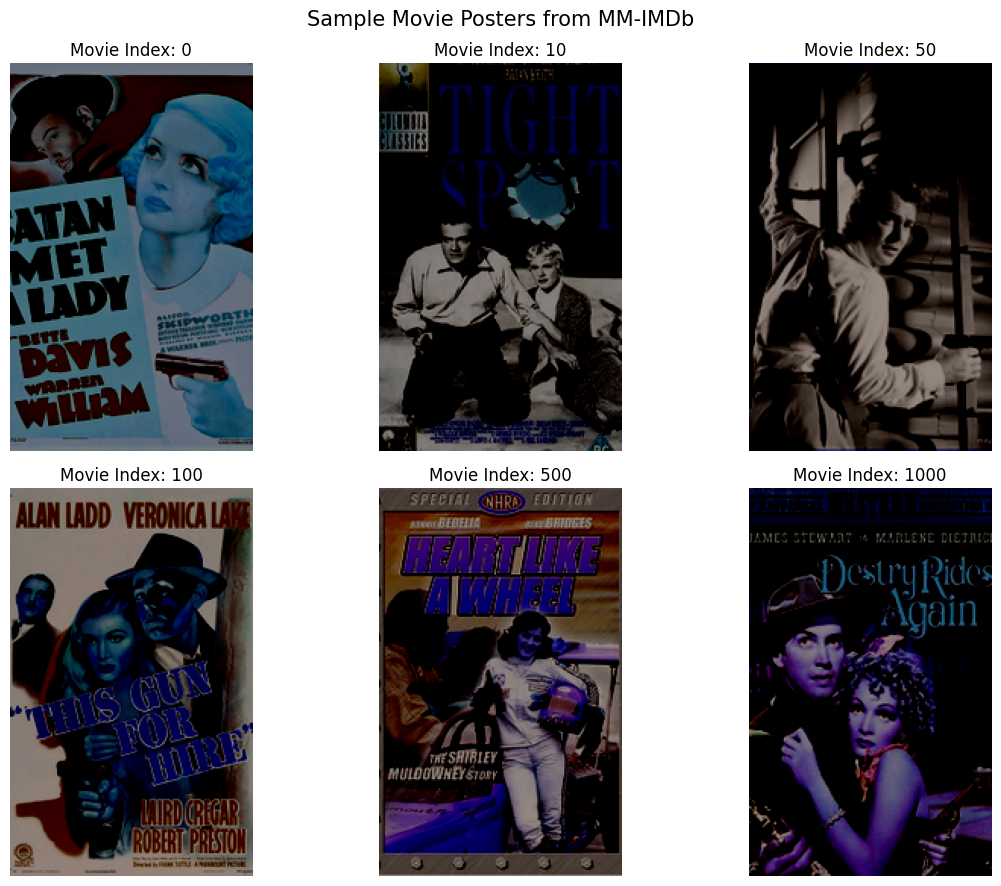

In [ ]:

# ============================================
# 1.5.2 VISUALISE SAMPLE MOVIE POSTERS
# ============================================

import matplotlib.pyplot as plt

# Select sample movie indices
sample_indices = [0, 10, 50, 100, 500, 1000]

with h5py.File(HDF5_PATH, "r") as hdf:

    fig, axes = plt.subplots(2, 3, figsize=(12, 9))

    for ax, idx in zip(axes.flatten(), sample_indices):

        # Read one poster
        image = hdf["images"][idx]

        # Convert CHW to HWC format
        image = np.transpose(image, (1, 2, 0))

        # Display poster
        ax.imshow(image)
        ax.set_title(f"Movie Index: {idx}")
        ax.axis("off")

    plt.suptitle(
        "Sample Movie Posters from MM-IMDb",
        fontsize=15
    )

    plt.tight_layout()
    plt.show()


Stage 1.5.3 – Investigate image preprocessing

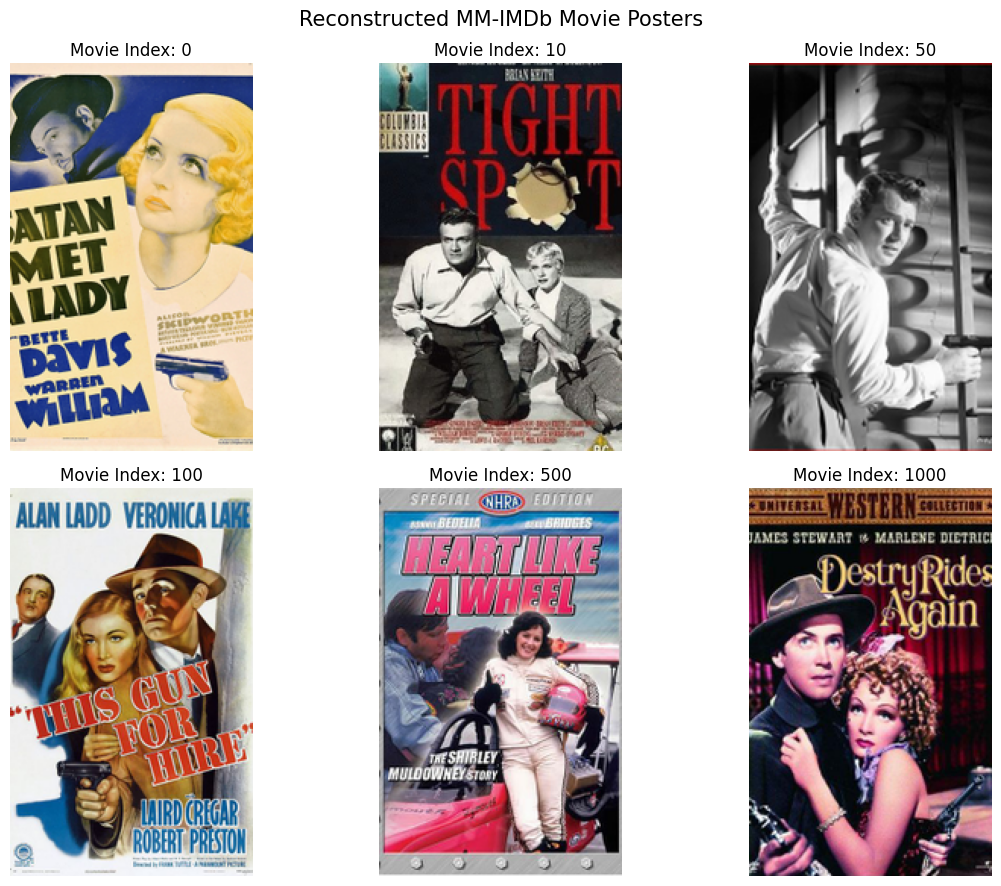

In [ ]:

# ============================================
# 1.5.3 RECONSTRUCT POSTERS FOR VISUALISATION
# ============================================

import numpy as np
import matplotlib.pyplot as plt
import h5py

# Common VGG preprocessing channel means (BGR order)
VGG_MEAN = np.array(
    [103.939, 116.779, 123.680],
    dtype=np.float32
).reshape(1, 1, 3)

sample_indices = [0, 10, 50, 100, 500, 1000]

fig, axes = plt.subplots(2, 3, figsize=(12, 9))

with h5py.File(HDF5_PATH, "r") as hdf:

    for ax, idx in zip(axes.flatten(), sample_indices):

        # Read image in channel-first format
        image = hdf["images"][idx]

        # Convert CHW to HWC
        image = np.transpose(image, (1, 2, 0)).astype(
            np.float32
        )

        # Reverse mean subtraction
        image = image + VGG_MEAN

        # Convert BGR to RGB
        image = image[:, :, ::-1]

        # Clip pixel values to valid display range
        image = np.clip(image, 0, 255).astype(np.uint8)

        ax.imshow(image)
        ax.set_title(f"Movie Index: {idx}")
        ax.axis("off")

plt.suptitle(
    "Reconstructed MM-IMDb Movie Posters",
    fontsize=15
)

plt.tight_layout()
plt.show()


Stage 1.6 – Text data exploration

Section 1.6.1 – Reconstruct plot summaries

In [ ]:

# ============================================
# 1.6.1 RECONSTRUCT TEXTUAL PLOT SUMMARIES
# ============================================

# Obtain vocabulary mapping
ix_to_word = metadata_dict["ix_to_word"]

# Convert numerical sequence into readable text
def decode_sequence(sequence, vocabulary):

    words = []

    for token in sequence:

        token = int(token)

        word = vocabulary.get(token, "_UNK_")

        words.append(word)

    return " ".join(words)


# Inspect sample plot summaries
with h5py.File(HDF5_PATH, "r") as hdf:

    sequences = hdf["sequences"]
    imdb_ids = hdf["imdb_ids"]

    print("=" * 60)
    print("SAMPLE MOVIE PLOT SUMMARIES")
    print("=" * 60)

    for idx in [0, 10, 50]:

        sequence = sequences[idx]

        plot = decode_sequence(
            sequence,
            ix_to_word
        )

        movie_id = imdb_ids[idx].decode("utf-8")

        print(f"\nMovie ID: {movie_id}")
        print("Token count:", len(sequence))
        print("Plot summary:")
        print(plot[:1500])
        print("-" * 60)


SAMPLE MOVIE PLOT SUMMARIES

Movie ID: 0028219
Token count: 204
Plot summary:
sardonic detective shane , thrown out of one town for bringing trouble , heads for home and his ex - partner ' s detective agency . the business is in a sad way , and shane , who has had the forethought to provide himself with a N - dollar commission from an old lady on the train , is welcomed with open arms . when pretty valerie purvis walks in the next day willing to pay over the odds to put a tail on the man who did her wrong , shane ' s way with the ladies looks like paying off yet again . but things start to go wrong when his partner is murdered , and shane himself comes home to find his apartment wrecked by a gentlemanly crook who comes back to apologise - - and to tell him a fascinating fairy - story about the fabled horn of roland that looks like not being so mythical after all . miss purvis wants protection . the police want answers . and all sorts of people want the ' french horn ' . . . but shane i

Stage 1.6.2 – Analyse plot summary lengths

PLOT SUMMARY LENGTH STATISTICS
count    25959.000000
mean       124.412766
std         90.470873
min          1.000000
25%         62.000000
50%        107.000000
75%        158.000000
max       1887.000000
dtype: float64
25th percentile: 62.0
50th percentile: 107.0
75th percentile: 158.0
90th percentile: 240.0
95th percentile: 301.0
99th percentile: 419.41999999999825


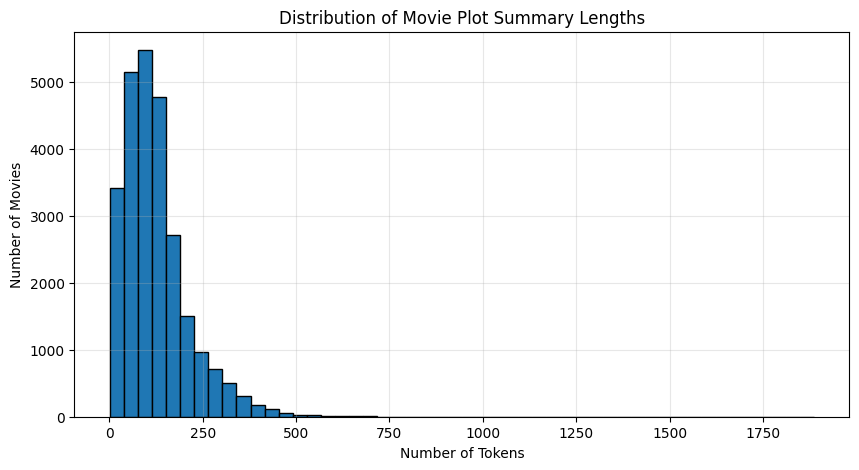

In [ ]:

# ============================================
# 1.6.2 PLOT SUMMARY LENGTH ANALYSIS
# ============================================

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import h5py

sequence_lengths = []

with h5py.File(HDF5_PATH, "r") as hdf:

    sequences = hdf["sequences"]

    for idx in range(len(sequences)):

        sequence = sequences[idx]

        sequence_lengths.append(len(sequence))

# Convert into DataFrame
text_stats = pd.Series(sequence_lengths)

print("=" * 60)
print("PLOT SUMMARY LENGTH STATISTICS")
print("=" * 60)

print(text_stats.describe())

# Calculate additional percentiles
for percentile in [25, 50, 75, 90, 95, 99]:

    print(
        f"{percentile}th percentile:",
        np.percentile(text_stats, percentile)
    )

# Visualise distribution
plt.figure(figsize=(10, 5))

plt.hist(
    text_stats,
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of Movie Plot Summary Lengths")
plt.xlabel("Number of Tokens")
plt.ylabel("Number of Movies")

plt.grid(alpha=0.3)
plt.show()


Stage 1.7 – Genre label exploration

Section 1.7.1 – Define genre labels and inspect target matrix

In [ ]:

# ============================================
# 1.7.1 DEFINE GENRES AND INSPECT LABEL MATRIX
# ============================================

# Define the documented MM-IMDb genre vocabulary
GENRE_NAMES = [
    "Drama", "Comedy", "Romance", "Thriller",
    "Crime", "Action", "Adventure", "Horror",
    "Documentary", "Mystery", "Sci-Fi", "Fantasy",
    "Family", "Biography", "War", "History",
    "Music", "Animation", "Musical", "Western",
    "Sport", "Short", "Film-Noir"
]

# Load genre labels
with h5py.File(HDF5_PATH, "r") as hdf:

    genre_matrix = hdf["genres"][:]

print("=" * 60)
print("GENRE LABEL MATRIX INFORMATION")
print("=" * 60)

print("Matrix shape:", genre_matrix.shape)
print("Number of movies:", genre_matrix.shape[0])
print("Number of genre categories:", genre_matrix.shape[1])

print("\nGenre vocabulary:")
for index, genre in enumerate(GENRE_NAMES):
    print(f"{index}: {genre}")

# Inspect sample labels
print("\nSample genre vectors:")

for i in range(5):
    print(f"Movie {i}:", genre_matrix[i])

# Check whether labels are binary
print("\nUnique label values:",
      np.unique(genre_matrix))

print("\nGenre matrix inspection completed.")


GENRE LABEL MATRIX INFORMATION
Matrix shape: (25959, 23)
Number of movies: 25959
Number of genre categories: 23

Genre vocabulary:
0: Drama
1: Comedy
2: Romance
3: Thriller
4: Crime
5: Action
6: Adventure
7: Horror
8: Documentary
9: Mystery
10: Sci-Fi
11: Fantasy
12: Family
13: Biography
14: War
15: History
16: Music
17: Animation
18: Musical
19: Western
20: Sport
21: Short
22: Film-Noir

Sample genre vectors:
Movie 0: [1 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1]
Movie 1: [1 0 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1]
Movie 2: [1 0 0 1 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1]
Movie 3: [1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1]
Movie 4: [1 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1]

Unique label values: [0 1]

Genre matrix inspection completed.


Section 1.7.2 – Analyse genre frequency and imbalance

In [ ]:

# ============================================
# 1.7.2 GENRE FREQUENCY ANALYSIS
# ============================================

# Count positive labels for each genre
genre_counts = genre_matrix.sum(axis=0)

# Calculate percentage of movies per genre
genre_percentages = (
    genre_counts / len(genre_matrix)
) * 100

# Create results DataFrame
genre_distribution = pd.DataFrame({
    "Genre": GENRE_NAMES,
    "Movie_Count": genre_counts,
    "Percentage": genre_percentages
})

# Sort by frequency
genre_distribution = genre_distribution.sort_values(
    by="Movie_Count",
    ascending=False
).reset_index(drop=True)

print("=" * 70)
print("GENRE DISTRIBUTION")
print("=" * 70)

print(
    genre_distribution.to_string(
        index=False,
        formatters={
            "Percentage": "{:.2f}%".format
        }
    )
)

print("\nMost frequent genre:",
      genre_distribution.iloc[0]["Genre"])

print("Least frequent genre:",
      genre_distribution.iloc[-1]["Genre"])


GENRE DISTRIBUTION
      Genre  Movie_Count Percentage
      Drama        13967     53.80%
     Comedy         8592     33.10%
    Romance         5364     20.66%
   Thriller         5192     20.00%
      Crime         3838     14.78%
     Action         3550     13.68%
  Adventure         2710     10.44%
     Horror         2703     10.41%
Documentary         2082      8.02%
    Mystery         2057      7.92%
     Sci-Fi         1991      7.67%
    Fantasy         1933      7.45%
     Family         1668      6.43%
  Biography         1343      5.17%
        War         1335      5.14%
    History         1143      4.40%
      Music         1045      4.03%
  Animation          997      3.84%
    Musical          841      3.24%
    Western          705      2.72%
      Sport          634      2.44%
      Short          471      1.81%
  Film-Noir          338      1.30%

Most frequent genre: Drama
Least frequent genre: Film-Noir


Section 1.7.3 – Visualise genre distribution

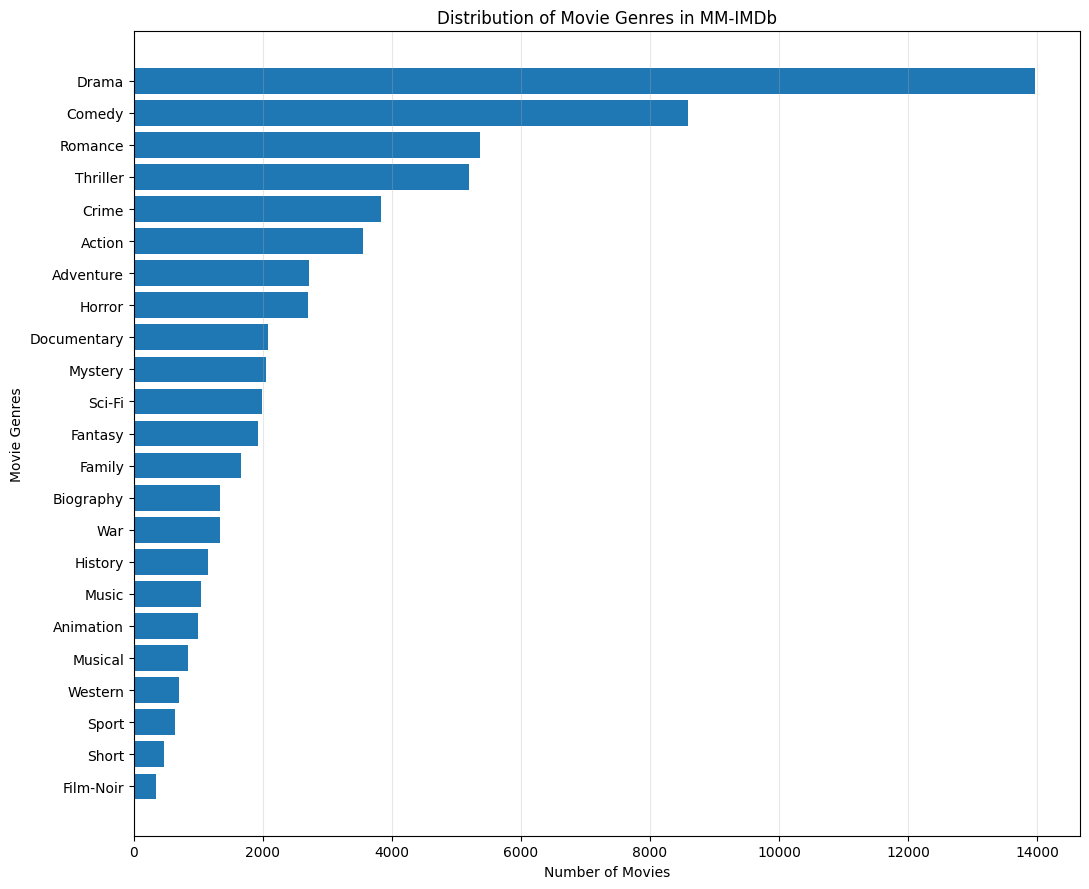

In [ ]:

# ============================================
# 1.7.3 VISUALISE GENRE DISTRIBUTION
# ============================================

plt.figure(figsize=(11, 9))

plt.barh(
    genre_distribution["Genre"],
    genre_distribution["Movie_Count"]
)

plt.xlabel("Number of Movies")
plt.ylabel("Movie Genres")

plt.title(
    "Distribution of Movie Genres in MM-IMDb"
)

plt.gca().invert_yaxis()

plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()


Section 1.7.4 – Analyse number of genres per movie

NUMBER OF GENRES PER MOVIE
count    25959.000000
mean         2.484649
std          1.188583
min          1.000000
25%          2.000000
50%          2.000000
75%          3.000000
max         10.000000
dtype: float64

Movies with one genre: 5965
Movies with two genres: 8211
Movies with three or more genres: 11783


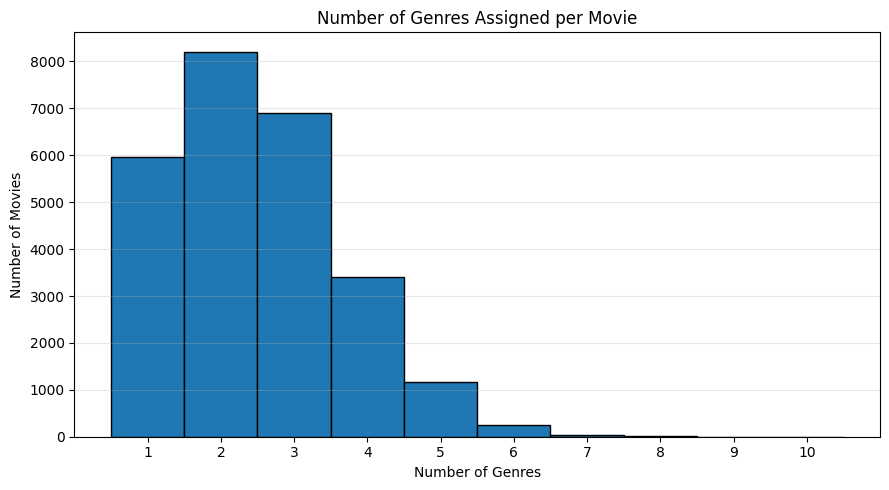

In [ ]:

# ============================================
# 1.7.4 NUMBER OF GENRES PER MOVIE
# ============================================

# Count positive genre labels for each movie
genres_per_movie = genre_matrix.sum(axis=1)

print("=" * 60)
print("NUMBER OF GENRES PER MOVIE")
print("=" * 60)

print(
    pd.Series(genres_per_movie).describe()
)

print("\nMovies with one genre:",
      np.sum(genres_per_movie == 1))

print("Movies with two genres:",
      np.sum(genres_per_movie == 2))

print("Movies with three or more genres:",
      np.sum(genres_per_movie >= 3))

# Visualise genre count distribution
plt.figure(figsize=(9, 5))

plt.hist(
    genres_per_movie,
    bins=np.arange(
        genres_per_movie.min() - 0.5,
        genres_per_movie.max() + 1.5,
        1
    ),
    edgecolor="black"
)

plt.title("Number of Genres Assigned per Movie")
plt.xlabel("Number of Genres")
plt.ylabel("Number of Movies")

plt.xticks(
    range(
        int(genres_per_movie.min()),
        int(genres_per_movie.max()) + 1
    )
)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


Section 1.7.5 – Verify genre ordering against known dataset statistics

In [ ]:

# ============================================
# 1.7.5 VERIFY GENRE COLUMN ORDERING
# ============================================

genre_count_check = {
    "Drama": 13967,
    "Film-Noir": 338
}

print("=" * 60)
print("GENRE ORDERING VERIFICATION")
print("=" * 60)

for genre, expected_count in genre_count_check.items():

    index = GENRE_NAMES.index(genre)
    actual_count = int(genre_matrix[:, index].sum())

    print(f"\nGenre: {genre}")
    print("Expected count:", expected_count)
    print("Observed count:", actual_count)
    print("Match:", actual_count == expected_count)

if (
    genre_matrix.shape[1] == len(GENRE_NAMES)
    and all(
        int(genre_matrix[:, GENRE_NAMES.index(g)].sum()) == c
        for g, c in genre_count_check.items()
    )
):
    print("\nEndpoint checks passed.")
    print("Further verification of all 23 columns is still required.")
else:
    print("\nWARNING: Genre ordering needs further investigation.")


GENRE ORDERING VERIFICATION

Genre: Drama
Expected count: 13967
Observed count: 13967
Match: True

Genre: Film-Noir
Expected count: 338
Observed count: 338
Match: True

Endpoint checks passed.
Further verification of all 23 columns is still required.


Stage 1.8 – Data quality assessment

Section 1.8.1 – Missing and invalid data analysis

In [ ]:

# ============================================
# 1.8.1 MISSING AND INVALID DATA ANALYSIS
# ============================================

import h5py
import numpy as np
import pandas as pd

quality_results = []

with h5py.File(HDF5_PATH, "r") as hdf:

    total_movies = hdf["genres"].shape[0]

    # 1. Check genre labels
    genres = hdf["genres"][:]

    invalid_genre_values = np.sum(
        ~np.isin(genres, [0, 1])
    )

    zero_label_movies = np.sum(
        genres.sum(axis=1) == 0
    )

    # 2. Check movie IDs
    movie_ids = [
        x.decode("utf-8")
        for x in hdf["imdb_ids"][:]
    ]

    missing_ids = sum(
        not x.strip() for x in movie_ids
    )

    # 3. Check plot sequences
    sequences = hdf["sequences"]

    empty_sequences = 0

    for i in range(total_movies):

        if len(sequences[i]) == 0:
            empty_sequences += 1

    # 4. Check numerical feature datasets
    feature_datasets = [
        "features",
        "three_grams",
        "vgg_features",
        "word_grams"
    ]

    for dataset_name in feature_datasets:

        dataset = hdf[dataset_name]

        nan_count = 0
        inf_count = 0

        for start in range(0, total_movies, 500):

            batch = dataset[start:start+500]

            nan_count += np.isnan(batch).sum()
            inf_count += np.isinf(batch).sum()

        quality_results.append({
            "Component": dataset_name,
            "Missing/NaN Values": int(nan_count),
            "Infinite Values": int(inf_count)
        })

# Display feature quality
quality_df = pd.DataFrame(quality_results)

print("=" * 65)
print("NUMERICAL FEATURE QUALITY")
print("=" * 65)

print(quality_df.to_string(index=False))

print("\nGENRE QUALITY")
print("Invalid label values:", invalid_genre_values)
print("Movies without any genre:", zero_label_movies)

print("\nIDENTIFIER QUALITY")
print("Missing movie IDs:", missing_ids)

print("\nTEXT QUALITY")
print("Empty plot sequences:", empty_sequences)


NUMERICAL FEATURE QUALITY
   Component  Missing/NaN Values  Infinite Values
    features                   0                0
 three_grams                   0                0
vgg_features                   0                0
  word_grams                   0                0

GENRE QUALITY
Invalid label values: 0
Movies without any genre: 0

IDENTIFIER QUALITY
Missing movie IDs: 0

TEXT QUALITY
Empty plot sequences: 0


Section 1.8.2 – Duplicate movie identification

In [ ]:

# ============================================
# 1.8.2 DUPLICATE MOVIE IDENTIFICATION
# ============================================

with h5py.File(HDF5_PATH, "r") as hdf:

    movie_ids = [
        x.decode("utf-8")
        for x in hdf["imdb_ids"][:]
    ]

# Create identifier frequency table
id_counts = pd.Series(movie_ids).value_counts()

# Identify duplicates
duplicate_ids = id_counts[id_counts > 1]

print("=" * 60)
print("DUPLICATE MOVIE ANALYSIS")
print("=" * 60)

print("Total movie records:", len(movie_ids))
print("Unique movie IDs:", len(set(movie_ids)))
print("Number of duplicated IDs:", len(duplicate_ids))

print(
    "Total records belonging to duplicated IDs:",
    int(duplicate_ids.sum())
)

if len(duplicate_ids) > 0:

    print("\nSample duplicate IDs:")
    print(duplicate_ids.head(10))

else:

    print("\nNo duplicate movie IDs detected.")


DUPLICATE MOVIE ANALYSIS
Total movie records: 25959
Unique movie IDs: 25959
Number of duplicated IDs: 0
Total records belonging to duplicated IDs: 0

No duplicate movie IDs detected.


Section 1.8.3 – Dataset consistency checks

In [ ]:

# ============================================
# 1.8.3 DATASET CONSISTENCY VERIFICATION
# ============================================

with h5py.File(HDF5_PATH, "r") as hdf:

    dataset_names = [
        "images",
        "sequences",
        "genres",
        "imdb_ids",
        "features",
        "vgg_features"
    ]

    print("=" * 60)
    print("MULTIMODAL DATASET CONSISTENCY")
    print("=" * 60)

    record_counts = {}

    for name in dataset_names:

        record_counts[name] = hdf[name].shape[0]

        print(
            f"{name:20s}: "
            f"{record_counts[name]:,} records"
        )

    consistent = (
        len(set(record_counts.values())) == 1
    )

    print("\nAll modalities aligned:", consistent)

    assert consistent, (
        "Dataset inconsistency detected!"
    )

print("\nConsistency verification completed.")


MULTIMODAL DATASET CONSISTENCY
images              : 25,959 records
sequences           : 25,959 records
genres              : 25,959 records
imdb_ids            : 25,959 records
features            : 25,959 records
vgg_features        : 25,959 records

All modalities aligned: True

Consistency verification completed.


Stage 1.9 – Final data quality summary

In [ ]:

# ============================================
# 1.9 FINAL DATA QUALITY SUMMARY
# ============================================

# Create a consolidated quality report
quality_summary = pd.DataFrame({
    "Quality Check": [
        "Total movie records",
        "Missing movie IDs",
        "Duplicate movie IDs",
        "Empty plot summaries",
        "Movies without genre labels",
        "Invalid genre values",
        "Feature NaN values",
        "Feature infinite values",
        "Multimodal record consistency"
    ],

    "Result": [
        25959,
        missing_ids,
        len(duplicate_ids),
        empty_sequences,
        zero_label_movies,
        invalid_genre_values,
        int(quality_df["Missing/NaN Values"].sum()),
        int(quality_df["Infinite Values"].sum()),
        "Verified" if consistent else "Failed"
    ]
})

print("=" * 65)
print("FINAL DATA QUALITY ASSESSMENT")
print("=" * 65)

print(quality_summary.to_string(index=False))

# Save the quality report
quality_summary.to_csv(
    f"{BASE_DIR}/results/data_quality_summary.csv",
    index=False
)

print("\nQuality report saved successfully.")


FINAL DATA QUALITY ASSESSMENT
                Quality Check   Result
          Total movie records    25959
            Missing movie IDs        0
          Duplicate movie IDs        0
         Empty plot summaries        0
  Movies without genre labels        0
         Invalid genre values        0
           Feature NaN values        0
      Feature infinite values        0
Multimodal record consistency Verified

Quality report saved successfully.


Stage 1.10 – Train, validation and test splitting

Section 1.10.1 – Install multi-label stratification library

In [ ]:

# ============================================
# 1.10.1 INSTALL ITERATIVE STRATIFICATION
# ============================================

!pip install -q iterative-stratification

print("Multi-label stratification library installed.")



Multi-label stratification library installed.


Section 1.10.2 – Create training, validation and test splits

In [ ]:

# ============================================
# 1.10.2 MULTI-LABEL DATASET SPLITTING
# ============================================

from iterstrat.ml_stratifiers import (
    MultilabelStratifiedShuffleSplit
)

# Configuration
RANDOM_SEED = 42
TEST_SIZE = 0.15
VALIDATION_SIZE = 0.15

# Original movie indices
movie_indices = np.arange(len(genre_matrix)).reshape(-1, 1)

# Multi-label target matrix
Y = genre_matrix.astype(np.int32)

# --------------------------------------------
# First split: 85% development, 15% testing
# --------------------------------------------

split_1 = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=TEST_SIZE,
    random_state=RANDOM_SEED
)

development_idx, test_idx = next(
    split_1.split(movie_indices, Y)
)

# --------------------------------------------
# Second split: 70% training, 15% validation
# --------------------------------------------

validation_relative_size = (
    VALIDATION_SIZE / (1 - TEST_SIZE)
)

split_2 = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=validation_relative_size,
    random_state=RANDOM_SEED
)

train_relative_idx, val_relative_idx = next(
    split_2.split(
        movie_indices[development_idx],
        Y[development_idx]
    )
)

# Convert relative indices to original indices
train_idx = development_idx[train_relative_idx]
val_idx = development_idx[val_relative_idx]

# --------------------------------------------
# Display split sizes
# --------------------------------------------

print("=" * 60)
print("DATASET SPLIT RESULTS")
print("=" * 60)

print("Training records:", len(train_idx))
print("Validation records:", len(val_idx))
print("Testing records:", len(test_idx))

print("Total records:",
      len(train_idx) + len(val_idx) + len(test_idx))

print("\nSplit percentages:")

for name, indices in [
    ("Training", train_idx),
    ("Validation", val_idx),
    ("Testing", test_idx)
]:

    percentage = len(indices) / len(Y) * 100

    print(f"{name}: {percentage:.2f}%")

# Verify no overlap
assert len(set(train_idx) & set(val_idx)) == 0
assert len(set(train_idx) & set(test_idx)) == 0
assert len(set(val_idx) & set(test_idx)) == 0

assert (
    len(train_idx) + len(val_idx) + len(test_idx)
    == len(Y)
)

print("\nAll split integrity checks passed!")


DATASET SPLIT RESULTS
Training records: 18146
Validation records: 3935
Testing records: 3878
Total records: 25959

Split percentages:
Training: 69.90%
Validation: 15.16%
Testing: 14.94%

All split integrity checks passed!


Section 1.10.3 – Verify genre distribution across splits

GENRE DISTRIBUTION ACROSS DATA SPLITS
      Genre Training_Percentage Validation_Percentage Testing_Percentage
      Drama              53.88%                53.24%             54.02%
     Comedy              33.14%                32.76%             33.24%
    Romance              20.69%                20.46%             20.76%
   Thriller              20.03%                19.80%             20.09%
      Crime              14.80%                14.64%             14.85%
     Action              13.69%                13.52%             13.74%
  Adventure              10.45%                10.32%             10.50%
     Horror              10.43%                10.32%             10.44%
Documentary               8.03%                 7.93%              8.05%
    Mystery               7.94%                 7.83%              7.97%
     Sci-Fi               7.68%                 7.60%              7.71%
    Fantasy               7.46%                 7.37%              7.48%
     Family  

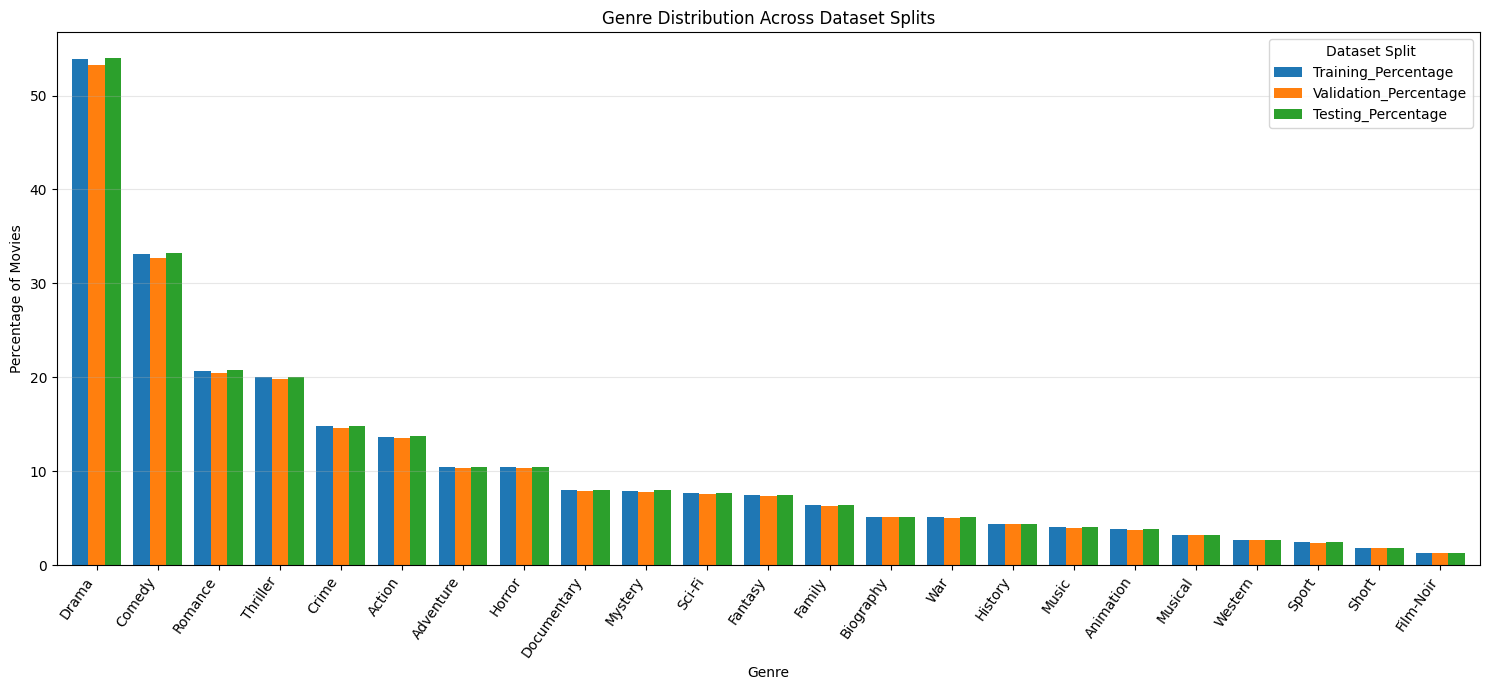

In [ ]:

# ============================================
# 1.10.3 VERIFY GENRE DISTRIBUTION
# ============================================

split_indices = {
    "Training": train_idx,
    "Validation": val_idx,
    "Testing": test_idx
}

split_distribution = pd.DataFrame({
    "Genre": GENRE_NAMES
})

for split_name, indices in split_indices.items():

    split_counts = Y[indices].sum(axis=0)

    split_percentages = (
        split_counts / len(indices)
    ) * 100

    split_distribution[
        f"{split_name}_Percentage"
    ] = split_percentages

print("=" * 80)
print("GENRE DISTRIBUTION ACROSS DATA SPLITS")
print("=" * 80)

print(
    split_distribution.to_string(
        index=False,
        formatters={
            col: "{:.2f}%".format
            for col in split_distribution.columns
            if col != "Genre"
        }
    )
)

# Visualise distribution
split_distribution.set_index("Genre").plot(
    kind="bar",
    figsize=(15, 7),
    width=0.8
)

plt.title("Genre Distribution Across Dataset Splits")
plt.xlabel("Genre")
plt.ylabel("Percentage of Movies")
plt.xticks(rotation=55, ha="right")
plt.legend(title="Dataset Split")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


Section 1.10.4 – Save dataset split indices

In [ ]:

# ============================================
# 1.10.4 SAVE DATASET SPLITS
# ============================================

SPLIT_PATH = f"{BASE_DIR}/results/dataset_splits.npz"

np.savez(
    SPLIT_PATH,
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx,
    random_seed=RANDOM_SEED
)

print("Dataset splits saved successfully!")
print("Location:", SPLIT_PATH)


Dataset splits saved successfully!
Location: /content/MM_IMDb_Project/results/dataset_splits.npz


In [ ]:

# ============================================
# 1.10.5 BACKUP PROJECT RESULTS TO GOOGLE DRIVE
# ============================================

from google.colab import drive
import os
import shutil

# Mount Google Drive
drive.mount("/content/drive")

# Create project backup directory
DRIVE_DIR = "/content/drive/MyDrive/MM_IMDb_Project"

os.makedirs(DRIVE_DIR, exist_ok=True)
os.makedirs(f"{DRIVE_DIR}/results", exist_ok=True)

# Backup dataset splits
shutil.copy2(
    f"{BASE_DIR}/results/dataset_splits.npz",
    f"{DRIVE_DIR}/results/dataset_splits.npz"
)

# Backup quality report
shutil.copy2(
    f"{BASE_DIR}/results/data_quality_summary.csv",
    f"{DRIVE_DIR}/results/data_quality_summary.csv"
)

print("Project results backed up successfully!")
print("Backup location:", DRIVE_DIR)


Mounted at /content/drive
Project results backed up successfully!
Backup location: /content/drive/MyDrive/MM_IMDb_Project


Stage 1.11 – Image preprocessing and feature extraction

In [ ]:

# ============================================
# RESTORE MM-IMDb PROJECT
# ============================================

from google.colab import drive
import os
import numpy as np
import pandas as pd

drive.mount('/content/drive')

BASE_DIR = '/content/MM_IMDb_Project'

DRIVE_DIR = (
    '/content/drive/MyDrive/MM_IMDb_Project'
)

# Restore previous dataset splits
split_data = np.load(
    f'{DRIVE_DIR}/results/dataset_splits.npz'
)

train_idx = split_data['train_idx']
val_idx = split_data['val_idx']
test_idx = split_data['test_idx']

# Restore quality assessment
quality_summary = pd.read_csv(
    f'{DRIVE_DIR}/results/data_quality_summary.csv'
)

print("PROJECT RESTORED")
print("Training:", len(train_idx))
print("Validation:", len(val_idx))
print("Testing:", len(test_idx))

display(quality_summary)


Mounted at /content/drive
PROJECT RESTORED
Training: 18146
Validation: 3935
Testing: 3878


,Quality Check,Result
0,Total movie records,25959
1,Missing movie IDs,0
2,Duplicate movie IDs,0
3,Empty plot summaries,0
4,Movies without genre labels,0
5,Invalid genre values,0
6,Feature NaN values,0
7,Feature infinite values,0
8,Multimodal record consistency,Verified


In [ ]:

# ============================================
# CHECK DATASET AVAILABILITY
# ============================================

import os

HDF5_PATH = (
    f'{BASE_DIR}/data/multimodal_imdb.hdf5'
)

METADATA_PATH = (
    f'{BASE_DIR}/data/metadata.npy'
)

print("HDF5 dataset:", os.path.exists(HDF5_PATH))
print("Metadata:", os.path.exists(METADATA_PATH))


HDF5 dataset: False
Metadata: False


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

!pip install -q kaggle

In [ ]:
!mkdir -p /content/drive/MyDrive/MM_IMDb_Project/data

!kaggle datasets download -d johnarevalo/mmimdb \
    -p /content/drive/MyDrive/MM_IMDb_Project/data \
    --unzip

Dataset URL: https://www.kaggle.com/datasets/johnarevalo/mmimdb
License(s): unknown
100% 3.65G/3.65G [03:12<00:00, 20.3MB/s]



In [ ]:
import os

DATA_DIR = "/content/drive/MyDrive/MM_IMDb_Project/data"

print("Files downloaded:")
for file in os.listdir(DATA_DIR):
    path = os.path.join(DATA_DIR, file)
    print(f"{file} — {os.path.getsize(path) / (1024**3):.2f} GB")

Files downloaded:
metadata.npy — 0.06 GB
multimodal_imdb.hdf5 — 14.57 GB


In [ ]:
import os
import numpy as np
import pandas as pd

# Project directories
BASE_DIR = "/content/MM_IMDb_Project"
DRIVE_DIR = "/content/drive/MyDrive/MM_IMDb_Project"

DATA_DIR = os.path.join(DRIVE_DIR, "data")
RESULTS_DIR = os.path.join(DRIVE_DIR, "results")

# Create local project folders
os.makedirs(BASE_DIR, exist_ok=True)
os.makedirs(os.path.join(BASE_DIR, "data"), exist_ok=True)
os.makedirs(os.path.join(BASE_DIR, "results"), exist_ok=True)
os.makedirs(os.path.join(BASE_DIR, "models"), exist_ok=True)

# Verify dataset files
assert os.path.exists(os.path.join(DATA_DIR, "metadata.npy"))
assert os.path.exists(os.path.join(DATA_DIR, "multimodal_imdb.hdf5"))

# Restore saved data splits
split_backup = np.load(os.path.join(RESULTS_DIR, "dataset_splits.npz"))

train_idx = split_backup["train_idx"]
val_idx = split_backup["val_idx"]
test_idx = split_backup["test_idx"]

# Restore data quality report
quality_summary = pd.read_csv(
    os.path.join(RESULTS_DIR, "data_quality_summary.csv")
)

print("Dataset files verified.")
print("Train samples:", len(train_idx))
print("Validation samples:", len(val_idx))
print("Test samples:", len(test_idx))
print("Total samples:", len(train_idx) + len(val_idx) + len(test_idx))
print("\nData quality report restored:")
display(quality_summary)

Dataset files verified.
Train samples: 18146
Validation samples: 3935
Test samples: 3878
Total samples: 25959

Data quality report restored:


,Quality Check,Result
0,Total movie records,25959
1,Missing movie IDs,0
2,Duplicate movie IDs,0
3,Empty plot summaries,0
4,Movies without genre labels,0
5,Invalid genre values,0
6,Feature NaN values,0
7,Feature infinite values,0
8,Multimodal record consistency,Verified


Section 1.12 – Verify the restored dataset and splits

In [ ]:
import h5py
import numpy as np
import os

HDF5_PATH = os.path.join(DATA_DIR, "multimodal_imdb.hdf5")

with h5py.File(HDF5_PATH, "r") as hdf:

    print("Dataset structure:")
    for key in hdf.keys():
        print(f"{key}: {hdf[key].shape}")

    total_records = hdf["genres"].shape[0]

    print("\nTotal records:", total_records)
    print("Genre labels:", hdf["genres"].shape)

# Verify split indices
all_indices = np.concatenate([train_idx, val_idx, test_idx])

print("\nSplit verification:")
print("Total split indices:", len(all_indices))
print("Unique indices:", len(np.unique(all_indices)))
print("Minimum index:", all_indices.min())
print("Maximum index:", all_indices.max())

assert len(all_indices) == total_records
assert len(np.unique(all_indices)) == total_records
assert all_indices.min() == 0
assert all_indices.max() == total_records - 1

print("\nSUCCESS: Dataset and splits are consistent.")

Dataset structure:
features: (25959, 300)
genres: (25959, 23)
images: (25959, 3, 256, 160)
imdb_ids: (25959,)
sequences: (25959,)
three_grams: (25959, 9946)
vgg_features: (25959, 4096)
word_grams: (25959, 13253)

Total records: 25959
Genre labels: (25959, 23)

Split verification:
Total split indices: 25959
Unique indices: 25959
Minimum index: 0
Maximum index: 25958

SUCCESS: Dataset and splits are consistent.


Section 1.13 – Inspect Existing Image Features (VGG).

In [ ]:
# Section 1.13: Inspect Existing VGG Image Features

import h5py
import numpy as np
import os

HDF5_PATH = os.path.join(DATA_DIR, "multimodal_imdb.hdf5")

with h5py.File(HDF5_PATH, "r") as hdf:

    vgg = hdf["vgg_features"]

    print("VGG Feature Information")
    print("-----------------------")
    print("Shape:", vgg.shape)
    print("Data type:", vgg.dtype)

    # Inspect a small sample rather than loading all features
    sample = vgg[:100]

    print("\nNumerical Statistics")
    print("--------------------")
    print("Minimum:", np.min(sample))
    print("Maximum:", np.max(sample))
    print("Mean:", np.mean(sample))
    print("Standard deviation:", np.std(sample))

    print("\nData Quality")
    print("------------")
    print("NaN values:", np.isnan(sample).sum())
    print("Infinite values:", np.isinf(sample).sum())
    print("All-zero feature rows:", np.sum(np.all(sample == 0, axis=1)))

    print("\nFirst movie feature vector:")
    print(vgg[0][:20])

VGG Feature Information
-----------------------
Shape: (25959, 4096)
Data type: float32

Numerical Statistics
--------------------
Minimum: 0.0
Maximum: 12.665962
Mean: 0.4931735
Standard deviation: 1.0864149

Data Quality
------------
NaN values: 0
Infinite values: 0
All-zero feature rows: 0

First movie feature vector:
[0.         0.         0.         0.         3.9483771  0.
 0.         0.         0.         2.3411007  0.         0.17642266
 0.88313127 3.2816787  0.         0.         0.         0.3568521
 0.         1.5543443 ]


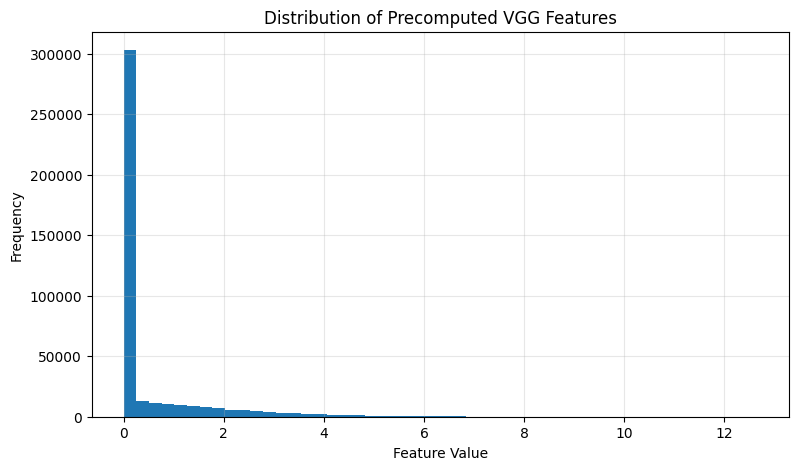

In [ ]:
# Visualise the distribution of VGG feature values

import matplotlib.pyplot as plt

with h5py.File(HDF5_PATH, "r") as hdf:
    sample = hdf["vgg_features"][:100]

plt.figure(figsize=(9, 5))
plt.hist(sample.flatten(), bins=50)
plt.title("Distribution of Precomputed VGG Features")
plt.xlabel("Feature Value")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)
plt.show()

Section 1.14 – Prepare Image Features


In [ ]:
# Section 1.14: Prepare Image Features

import h5py
import numpy as np
import os

HDF5_PATH = os.path.join(DATA_DIR, "multimodal_imdb.hdf5")

# Load VGG features and genre labels
with h5py.File(HDF5_PATH, "r") as hdf:
    image_features = hdf["vgg_features"][:].astype(np.float32)
    labels = hdf["genres"][:].astype(np.float32)

print("Image feature shape:", image_features.shape)
print("Genre label shape:", labels.shape)

# Verify alignment
assert image_features.shape[0] == labels.shape[0]
assert image_features.shape[0] == 25959
assert labels.shape[1] == 23

# Check numerical validity across the full feature matrix
assert np.isfinite(image_features).all()
assert np.isfinite(labels).all()

print("\nFull feature matrix contains no NaN or infinite values.")

# Apply the previously saved split indices
X_img_train = image_features[train_idx]
X_img_val = image_features[val_idx]
X_img_test = image_features[test_idx]

y_train = labels[train_idx]
y_val = labels[val_idx]
y_test = labels[test_idx]

print("\nPrepared image datasets:")
print("Training:", X_img_train.shape, y_train.shape)
print("Validation:", X_img_val.shape, y_val.shape)
print("Testing:", X_img_test.shape, y_test.shape)

# Save prepared data to Google Drive
OUTPUT_PATH = os.path.join(RESULTS_DIR, "prepared_image_features.npz")

np.savez_compressed(
    OUTPUT_PATH,
    X_img_train=X_img_train,
    X_img_val=X_img_val,
    X_img_test=X_img_test,
    y_train=y_train,
    y_val=y_val,
    y_test=y_test
)

print("\nSaved prepared image features to:", OUTPUT_PATH)

Image feature shape: (25959, 4096)
Genre label shape: (25959, 23)

Full feature matrix contains no NaN or infinite values.

Prepared image datasets:
Training: (18146, 4096) (18146, 23)
Validation: (3935, 4096) (3935, 23)
Testing: (3878, 4096) (3878, 23)

Saved prepared image features to: /content/drive/MyDrive/MM_IMDb_Project/results/prepared_image_features.npz


Section 2.1 – Build the Poster-Only Classification Model

2.1.1 – Feature Standardisation

In [ ]:
# Section 2.1.1: Feature Standardisation

from sklearn.preprocessing import StandardScaler
import joblib
import os

# Create scaler
scaler = StandardScaler()

# Fit only on training data
X_img_train_scaled = scaler.fit_transform(X_img_train)

# Apply the same transformation to validation and test data
X_img_val_scaled = scaler.transform(X_img_val)
X_img_test_scaled = scaler.transform(X_img_test)

print("Standardisation completed.")

print("Training mean:", X_img_train_scaled.mean())
print("Training standard deviation:", X_img_train_scaled.std())

# Save scaler for future reuse
SCALER_PATH = os.path.join(RESULTS_DIR, "image_feature_scaler.pkl")

joblib.dump(scaler, SCALER_PATH)

print("Scaler saved:", SCALER_PATH)

Standardisation completed.
Training mean: -1.05111246e-10
Training standard deviation: 0.99841183
Scaler saved: /content/drive/MyDrive/MM_IMDb_Project/results/image_feature_scaler.pkl


2.1.2 – Handling Genre Imbalance

In [ ]:
import numpy as np
import torch

# Calculate positive and negative counts from training labels
positive_counts = y_train.sum(axis=0)
negative_counts = len(y_train) - positive_counts

# Calculate positive weights
pos_weights = negative_counts / positive_counts

print("Number of genres:", len(pos_weights))
print("Minimum positive weight:", pos_weights.min())
print("Maximum positive weight:", pos_weights.max())

# Convert to PyTorch tensor
pos_weights_tensor = torch.tensor(
    pos_weights,
    dtype=torch.float32
)

Number of genres: 23
Minimum positive weight: 0.85598856
Maximum positive weight: 75.88983


Section 2.1.3 – Define the Poster-Only Neural Network

In [ ]:
# Section 2.1.3: Define Poster-Only Neural Network

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Select available computing device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Computing device:", device)

# Define neural network
class PosterOnlyMLP(nn.Module):

    def __init__(self, input_size=4096, hidden_size=512, output_size=23):
        super(PosterOnlyMLP, self).__init__()

        self.network = nn.Sequential(

            # First fully connected layer
            nn.Linear(input_size, hidden_size),

            # Activation function
            nn.ReLU(),

            # Dropout for regularisation
            nn.Dropout(0.4),

            # Output layer
            nn.Linear(hidden_size, output_size)
        )

    def forward(self, x):
        return self.network(x)


# Initialise model
image_model = PosterOnlyMLP().to(device)

print("\nPoster-only model architecture:")
print(image_model)

# Define loss function with class imbalance weights
criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weights_tensor.to(device)
)

# Define optimiser
optimizer = torch.optim.Adam(
    image_model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

print("\nLoss function:", criterion)
print("Optimiser:", optimizer)

Computing device: cpu

Poster-only model architecture:
PosterOnlyMLP(
  (network): Sequential(
    (0): Linear(in_features=4096, out_features=512, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.4, inplace=False)
    (3): Linear(in_features=512, out_features=23, bias=True)
  )
)

Loss function: BCEWithLogitsLoss()
Optimiser: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)


2.1.4 – Prepare Training and Validation DataLoaders

In [ ]:
# Convert features and labels into PyTorch tensors

X_train_tensor = torch.tensor(
    X_img_train_scaled, dtype=torch.float32
)

X_val_tensor = torch.tensor(
    X_img_val_scaled, dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train, dtype=torch.float32
)

y_val_tensor = torch.tensor(
    y_val, dtype=torch.float32
)

# Create datasets
train_dataset = TensorDataset(
    X_train_tensor, y_train_tensor
)

val_dataset = TensorDataset(
    X_val_tensor, y_val_tensor
)

# Create DataLoaders
BATCH_SIZE = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Batch size:", BATCH_SIZE)

Training batches: 142
Validation batches: 31
Batch size: 128


Section 2.1.5 – Train the Poster-Only Model

In [ ]:
# Section 2.1.5: Training Configuration

import copy
import torch
import numpy as np
import pandas as pd
import os

# Training settings
EPOCHS = 20
PATIENCE = 4

best_val_loss = float("inf")
patience_counter = 0

# Store training history
history = {
    "epoch": [],
    "train_loss": [],
    "val_loss": []
}

# Checkpoint location in Google Drive
CHECKPOINT_PATH = os.path.join(
    RESULTS_DIR,
    "poster_only_best_model.pth"
)

print("Maximum epochs:", EPOCHS)
print("Early stopping patience:", PATIENCE)
print("Checkpoint path:", CHECKPOINT_PATH)
print("Training device:", device)

Maximum epochs: 20
Early stopping patience: 4
Checkpoint path: /content/drive/MyDrive/MM_IMDb_Project/results/poster_only_best_model.pth
Training device: cpu


In [ ]:
# Train the poster-only model

for epoch in range(EPOCHS):

    # -------------------------
    # Training phase
    # -------------------------
    image_model.train()
    running_train_loss = 0.0

    for batch_features, batch_labels in train_loader:

        batch_features = batch_features.to(device)
        batch_labels = batch_labels.to(device)

        # Reset gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = image_model(batch_features)

        # Calculate loss
        loss = criterion(outputs, batch_labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        running_train_loss += loss.item()

    train_loss = running_train_loss / len(train_loader)

    # -------------------------
    # Validation phase
    # -------------------------
    image_model.eval()
    running_val_loss = 0.0

    with torch.no_grad():

        for batch_features, batch_labels in val_loader:

            batch_features = batch_features.to(device)
            batch_labels = batch_labels.to(device)

            outputs = image_model(batch_features)

            loss = criterion(outputs, batch_labels)

            running_val_loss += loss.item()

    val_loss = running_val_loss / len(val_loader)

    # Record results
    history["epoch"].append(epoch + 1)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"Training Loss: {train_loss:.4f} | "
        f"Validation Loss: {val_loss:.4f}"
    )

    # Save best model
    if val_loss < best_val_loss:

        best_val_loss = val_loss
        patience_counter = 0

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": image_model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_loss": best_val_loss
        }, CHECKPOINT_PATH)

        print("  Best model checkpoint saved.")

    else:
        patience_counter += 1
        print(f"  No improvement: {patience_counter}/{PATIENCE}")

    # Early stopping
    if patience_counter >= PATIENCE:

        print("\nEarly stopping triggered.")
        break

# Save training history
history_df = pd.DataFrame(history)

history_path = os.path.join(
    RESULTS_DIR,
    "poster_only_training_history.csv"
)

history_df.to_csv(history_path, index=False)

print("\nTraining completed.")
print("Best validation loss:", round(best_val_loss, 4))
print("Best checkpoint:", CHECKPOINT_PATH)
print("Training history:", history_path)

Epoch [1/20] Training Loss: 1.1467 | Validation Loss: 1.0592
  Best model checkpoint saved.
Epoch [2/20] Training Loss: 0.9276 | Validation Loss: 1.0830
  No improvement: 1/4
Epoch [3/20] Training Loss: 0.8334 | Validation Loss: 1.1337
  No improvement: 2/4
Epoch [4/20] Training Loss: 0.7628 | Validation Loss: 1.2307
  No improvement: 3/4
Epoch [5/20] Training Loss: 0.7064 | Validation Loss: 1.3453
  No improvement: 4/4

Early stopping triggered.

Training completed.
Best validation loss: 1.0592
Best checkpoint: /content/drive/MyDrive/MM_IMDb_Project/results/poster_only_best_model.pth
Training history: /content/drive/MyDrive/MM_IMDb_Project/results/poster_only_training_history.csv


Section 2.1.6 – Visualise training performance

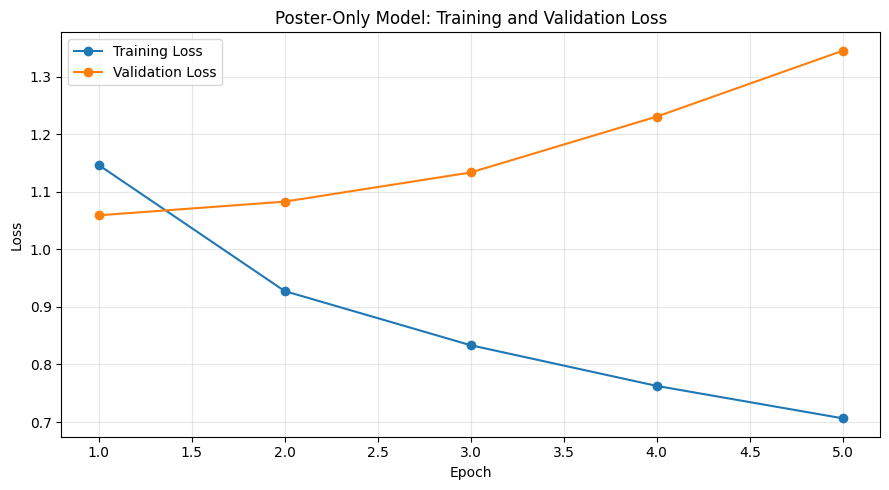

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Poster-Only Model: Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

2.1.7 – Restore the Best Poster-Only Model

In [ ]:
# Restore the best checkpoint from Google Drive

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=True
)

image_model.load_state_dict(checkpoint["model_state_dict"])
image_model.eval()

print("Best model restored successfully.")
print("Best epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["best_val_loss"])

Best model restored successfully.
Best epoch: 1
Best validation loss: 1.0591924248203155


2.1.8 – Poster-Only Model Evaluation

In [ ]:
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    average_precision_score
)

# Generate validation predictions
all_outputs = []

image_model.eval()

with torch.no_grad():
    for batch_features, _ in val_loader:

        batch_features = batch_features.to(device)

        logits = image_model(batch_features)

        probabilities = torch.sigmoid(logits)

        all_outputs.append(probabilities.cpu().numpy())

# Combine batch predictions
y_val_prob = np.vstack(all_outputs)

# Convert probabilities into binary predictions
y_val_pred = (y_val_prob >= 0.5).astype(int)

# Calculate evaluation metrics
metrics = {
    "Micro F1": f1_score(
        y_val, y_val_pred, average="micro", zero_division=0
    ),
    "Macro F1": f1_score(
        y_val, y_val_pred, average="macro", zero_division=0
    ),
    "Micro Precision": precision_score(
        y_val, y_val_pred, average="micro", zero_division=0
    ),
    "Micro Recall": recall_score(
        y_val, y_val_pred, average="micro", zero_division=0
    ),
    "Macro Average Precision": average_precision_score(
        y_val, y_val_prob, average="macro"
    ),
    "Micro Average Precision": average_precision_score(
        y_val, y_val_prob, average="micro"
    )
}

print("Poster-Only Model: Validation Results")
print("--------------------------------------")

for name, value in metrics.items():
    print(f"{name}: {value:.4f}")

Poster-Only Model: Validation Results
--------------------------------------
Micro F1: 0.2992
Macro F1: 0.2655
Micro Precision: 0.1921
Micro Recall: 0.6761
Macro Average Precision: 0.2753
Micro Average Precision: 0.2346


2.1.9 – Prediction Threshold Optimisation

In [ ]:
# Section 2.1.9: Threshold Optimisation

from sklearn.metrics import f1_score
import pandas as pd
import numpy as np

thresholds = np.arange(0.10, 0.91, 0.05)

threshold_results = []

for threshold in thresholds:

    predictions = (y_val_prob >= threshold).astype(int)

    micro_f1 = f1_score(
        y_val,
        predictions,
        average="micro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_val,
        predictions,
        average="macro",
        zero_division=0
    )

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Micro F1": micro_f1,
        "Macro F1": macro_f1
    })

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df.round(4)
)

# Identify best thresholds for both metrics
best_micro = threshold_df.loc[
    threshold_df["Micro F1"].idxmax()
]

best_macro = threshold_df.loc[
    threshold_df["Macro F1"].idxmax()
]

print("\nBest threshold for Micro F1:")
print(best_micro)

print("\nBest threshold for Macro F1:")
print(best_macro)

,Threshold,Micro F1,Macro F1
0,0.10,0.2176,0.1910
1,0.15,0.2285,0.1995
2,0.20,0.2401,0.2089
3,0.25,0.2503,0.2177
4,0.30,0.2612,0.2273
5,0.35,0.2717,0.2366
6,0.40,0.2825,0.2473
7,0.45,0.2923,0.2577
8,0.50,0.2992,0.2655
9,0.55,0.3048,0.2720



Best threshold for Micro F1:
Threshold    0.600000
Micro F1     0.307683
Macro F1     0.276841
Name: 10, dtype: float64

Best threshold for Macro F1:
Threshold    0.600000
Micro F1     0.307683
Macro F1     0.276841
Name: 10, dtype: float64


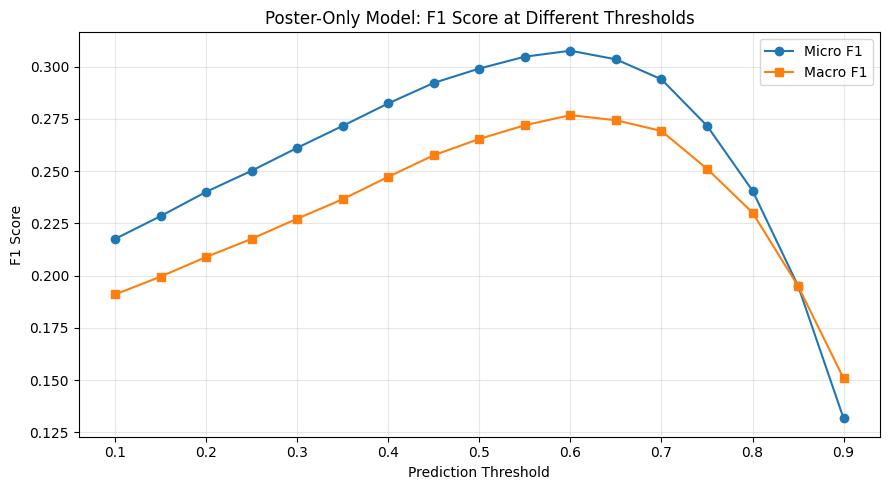

In [ ]:
# Visualise threshold performance

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Micro F1"],
    marker="o",
    label="Micro F1"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Macro F1"],
    marker="s",
    label="Macro F1"
)

plt.xlabel("Prediction Threshold")
plt.ylabel("F1 Score")
plt.title("Poster-Only Model: F1 Score at Different Thresholds")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

2.1.10 – Save Optimal Prediction Threshold

In [ ]:
# Save threshold optimisation results

OPTIMAL_IMAGE_THRESHOLD = 0.60

threshold_df.to_csv(
    os.path.join(RESULTS_DIR, "poster_threshold_results.csv"),
    index=False
)

np.save(
    os.path.join(RESULTS_DIR, "poster_optimal_threshold.npy"),
    OPTIMAL_IMAGE_THRESHOLD
)

print("Selected threshold:", OPTIMAL_IMAGE_THRESHOLD)
print("Threshold results saved successfully.")

Selected threshold: 0.6
Threshold results saved successfully.


Section 2.2 – Inspect Text Representations

2.2.1 – Inspect Text Features and Token Sequences

In [ ]:
# Section 2.2.1: Inspect Text Representations

import h5py
import numpy as np
import os

HDF5_PATH = os.path.join(DATA_DIR, "multimodal_imdb.hdf5")

with h5py.File(HDF5_PATH, "r") as hdf:

    # Inspect 300-dimensional text features
    text_features = hdf["features"]

    print("TEXT FEATURES")
    print("-------------------------")
    print("Shape:", text_features.shape)
    print("Data type:", text_features.dtype)

    sample_features = text_features[:100]

    print("Minimum:", sample_features.min())
    print("Maximum:", sample_features.max())
    print("Mean:", sample_features.mean())
    print("Standard deviation:", sample_features.std())
    print("NaN values:", np.isnan(sample_features).sum())
    print("Infinite values:", np.isinf(sample_features).sum())

    # Inspect plot token sequences
    sequences = hdf["sequences"]

    print("\nTEXT SEQUENCES")
    print("-------------------------")
    print("Number of sequences:", len(sequences))

    for i in range(3):
        sequence = sequences[i]
        print(f"\nMovie {i + 1}")
        print("Sequence length:", len(sequence))
        print("First 20 tokens:", sequence[:20])

TEXT FEATURES
-------------------------
Shape: (25959, 300)
Data type: float32
Minimum: -0.16725215
Maximum: 0.21916199
Mean: -0.0007412673
Standard deviation: 0.047548205
NaN values: 0
Infinite values: 0

TEXT SEQUENCES
-------------------------
Number of sequences: 25959

Movie 1
Sequence length: 204
First 20 tokens: [18186   418  5100     1  1562    40     7    37   112    18  1805   544
     1   923    18    94     5    10   317    14]

Movie 2
Sequence length: 87
First 20 tokens: [    4 11310   148   628   655     1     4    53    19    28    80  5064
     6   192  3756 22755     5     4  1998   208]

Movie 3
Sequence length: 259
First 20 tokens: [ 3065     6     2   719   672  3659  2116     1     2   912     9 11399
   314     5  3579   896  1276     8     2   258]


In [1]:
# Restore project paths and verify saved files

import os
import numpy as np
import torch

DRIVE_DIR = "/content/drive/MyDrive/MM_IMDb_Project"
DATA_DIR = os.path.join(DRIVE_DIR, "data")
RESULTS_DIR = os.path.join(DRIVE_DIR, "results")

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nDataset files:")
print(os.listdir(DATA_DIR))

print("\nSaved project results:")
print(os.listdir(RESULTS_DIR))

GPU available: True
GPU: Tesla T4

Dataset files:


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/MM_IMDb_Project/data'

In [2]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os

print("My Drive contents:")

for item in os.listdir('/content/drive/MyDrive'):
    print(item)

My Drive contents:
7671BBCE-9572-4172-B203-A22AEECE4126.jpeg
CODE.pdf
F9DFE99D-28E2-4F74-8B25-7D77A3D21E24.jpeg
SAHANA K V IEEE.gdoc
SAHANA K V IEEE.docx
Connection techy (1).docx
Copy of Connection techy.gdoc
Connection techy.docx
Tanusri S DC.JPG
Edusoc 1st year.gdoc
QUORA
1 - 6.gdoc
mkx-wyvo-akz – 5 Jan 2023 (1).pdf
mkx-wyvo-akz – 5 Jan 2023.pdf
PPT - Submarine Communication Using Blue Green Laser.pdf
PPT - Submarine Communication Using Blue Green Laser.gdoc
Untitled spreadsheet (1).gsheet
Untitled document (21).gdoc
Colab Notebooks
Screenshot (22).png
IMG_3367.jpeg
IMG_3368.jpeg
Fwd Webform submission from.pdf
Fwd Webform submission from.gdoc
SOMASUNDARAMAN.gdoc
 SAHANA K V.gdoc
DAA UNIT 1 2M.gdoc
SEC IEEE EDUCATION SOCIETY STUDENT BRANCH CHAPTER.gdoc
MACHINE LEARNING.gdoc
SIH 2023.gdoc
Untitled document (20).gdoc
prediction.gdoc
Sahana ML.gdoc
e office.docx
unity 5 qn 1.gdoc
Wealth Certificate.gdoc
Sponsorship Affidavit_Sriram.gdoc
Untitled document (19).gdoc
EEE Front page.gdoc
T

In [4]:
import os
import numpy as np
import torch

DRIVE_DIR = "/content/drive/MyDrive/MM_IMDb_Project"
DATA_DIR = os.path.join(DRIVE_DIR, "data")
RESULTS_DIR = os.path.join(DRIVE_DIR, "results")

print("GPU:", torch.cuda.get_device_name(0))

print("\nDataset files:")
print(os.listdir(DATA_DIR))

print("\nSaved results:")
print(os.listdir(RESULTS_DIR))

GPU: Tesla T4

Dataset files:
['metadata.npy', 'multimodal_imdb.hdf5']

Saved results:
['data_quality_summary.csv', 'dataset_splits.npz', 'prepared_image_features.npz', 'image_feature_scaler.pkl', 'poster_only_best_model.pth', 'poster_only_training_history.csv', 'poster_threshold_results.csv', 'poster_optimal_threshold.npy']


Section 2.2.2 – Reconstruct Movie Plot Summaries

In [5]:
import numpy as np
import os

METADATA_PATH = os.path.join(DATA_DIR, "metadata.npy")

metadata = np.load(
    METADATA_PATH,
    allow_pickle=True
).item()

print("Metadata keys:", metadata.keys())
print("Vocabulary size:", metadata["vocab_size"])

ix_to_word = metadata["ix_to_word"]
word_to_ix = metadata["word_to_ix"]

print("Index-to-word mapping size:", len(ix_to_word))
print("Word-to-index mapping size:", len(word_to_ix))

print("\nFirst 15 vocabulary entries:")

for i in range(15):
    print(i, ":", ix_to_word[i])

Metadata keys: dict_keys(['lookup', 'vocab_size', 'word_to_ix', 'ix_to_word'])
Vocabulary size: 69980
Index-to-word mapping size: 69980
Word-to-index mapping size: 69980

First 15 vocabulary entries:
0 : _UNK_
1 : ,
2 : the
3 : .
4 : a
5 : and
6 : to
7 : of
8 : in
9 : is
10 : his
11 : '
12 : he
13 : s
14 : -


Section 2.2.2 – Reconstruct Movie Plot Summaries

Code cell 2 – Reconstruct three movie summaries

In [6]:
# Reconstruct movie plot summaries from token sequences

import h5py

HDF5_PATH = os.path.join(DATA_DIR, "multimodal_imdb.hdf5")

with h5py.File(HDF5_PATH, "r") as hdf:

    sequences = hdf["sequences"]

    for i in range(3):

        token_ids = sequences[i]

        words = [
            ix_to_word[int(token)]
            for token in token_ids
            if int(token) in ix_to_word
        ]

        plot = " ".join(words)

        print(f"\nMOVIE {i + 1}")
        print("-" * 60)
        print("Token count:", len(token_ids))
        print("Reconstructed plot:")
        print(plot[:1500])


MOVIE 1
------------------------------------------------------------
Token count: 204
Reconstructed plot:
sardonic detective shane , thrown out of one town for bringing trouble , heads for home and his ex - partner ' s detective agency . the business is in a sad way , and shane , who has had the forethought to provide himself with a N - dollar commission from an old lady on the train , is welcomed with open arms . when pretty valerie purvis walks in the next day willing to pay over the odds to put a tail on the man who did her wrong , shane ' s way with the ladies looks like paying off yet again . but things start to go wrong when his partner is murdered , and shane himself comes home to find his apartment wrecked by a gentlemanly crook who comes back to apologise - - and to tell him a fascinating fairy - story about the fabled horn of roland that looks like not being so mythical after all . miss purvis wants protection . the police want answers . and all sorts of people want the ' fr

Code cell 3 – Verify vocabulary coverage

In [7]:
# Verify that all token IDs have corresponding vocabulary entries

with h5py.File(HDF5_PATH, "r") as hdf:

    sequences = hdf["sequences"]

    total_tokens = 0
    unmapped_tokens = 0
    maximum_token_id = 0

    for sequence in sequences:

        for token in sequence:

            token = int(token)
            total_tokens += 1

            maximum_token_id = max(maximum_token_id, token)

            if token not in ix_to_word:
                unmapped_tokens += 1

print("Total tokens:", total_tokens)
print("Unmapped tokens:", unmapped_tokens)
print("Maximum token ID:", maximum_token_id)

coverage = (
    (1 - unmapped_tokens / total_tokens) * 100
)

print("Vocabulary coverage:", round(coverage, 2), "%")

Total tokens: 3229631
Unmapped tokens: 0
Maximum token ID: 69979
Vocabulary coverage: 100.0 %


Section 2.2.4 – Prepare Text Dataset

In [8]:
!pip install -q transformers

In [9]:
import torch
import numpy as np
import h5py
import os

from transformers import (
    AutoTokenizer,
    AutoModel
)

# Select pretrained text encoder
MODEL_NAME = "distilbert-base-uncased"

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Tokenizer loaded successfully.")
print("Model:", MODEL_NAME)
print("Vocabulary size:", tokenizer.vocab_size)
print("Maximum model length:", tokenizer.model_max_length)

# Confirm GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Computing device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokenizer loaded successfully.
Model: distilbert-base-uncased
Vocabulary size: 30522
Maximum model length: 512
Computing device: cuda
GPU: Tesla T4


In [10]:
# Section 2.2.5: Test DistilBERT Tokenisation

with h5py.File(HDF5_PATH, "r") as hdf:

    sequences = hdf["sequences"]

    for i in range(3):

        token_ids = sequences[i]

        plot = " ".join(
            ix_to_word[int(token)]
            for token in token_ids
        )

        encoded = tokenizer(
            plot,
            truncation=True,
            max_length=256,
            padding="max_length",
            return_tensors="pt"
        )

        print(f"\nMovie {i + 1}")
        print("Original words:", len(token_ids))
        print("DistilBERT tokens:", encoded["attention_mask"].sum().item())
        print("Input tensor shape:", encoded["input_ids"].shape)


Movie 1
Original words: 204
DistilBERT tokens: 218
Input tensor shape: torch.Size([1, 256])

Movie 2
Original words: 87
DistilBERT tokens: 95
Input tensor shape: torch.Size([1, 256])

Movie 3
Original words: 259
DistilBERT tokens: 256
Input tensor shape: torch.Size([1, 256])


2.2.6 – Load and Configure Pretrained DistilBERT

In [11]:
# Section 2.2.6: Load DistilBERT Encoder

from transformers import AutoModel

# Load pretrained DistilBERT
text_encoder = AutoModel.from_pretrained(MODEL_NAME)

# Freeze pretrained parameters
for parameter in text_encoder.parameters():
    parameter.requires_grad = False

# Move model to GPU
text_encoder = text_encoder.to(device)

# Set evaluation mode
text_encoder.eval()

# Verify configuration
total_parameters = sum(
    parameter.numel()
    for parameter in text_encoder.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in text_encoder.parameters()
    if parameter.requires_grad
)

print("DistilBERT loaded successfully.")
print("Total parameters:", total_parameters)
print("Trainable parameters:", trainable_parameters)
print("Hidden dimensions:", text_encoder.config.hidden_size)
print("Device:", next(text_encoder.parameters()).device)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


DistilBERT loaded successfully.
Total parameters: 66362880
Trainable parameters: 0
Hidden dimensions: 768
Device: cuda:0


2.2.7 – Extract and Save DistilBERT Text Embeddings

In [13]:
# Section 2.2.7: Extract DistilBERT Text Embeddings

import numpy as np
import h5py
import torch
import os

MAX_LENGTH = 256
BATCH_SIZE_TEXT = 16

NUM_MOVIES = 25959
HIDDEN_SIZE = 768

EMBEDDING_PATH = os.path.join(
    RESULTS_DIR,
    "distilbert_text_embeddings.npy"
)

PROGRESS_PATH = os.path.join(
    RESULTS_DIR,
    "text_extraction_progress.txt"
)

# Create output array
text_embeddings = np.lib.format.open_memmap(
    EMBEDDING_PATH,
    mode="w+",
    dtype=np.float32,
    shape=(NUM_MOVIES, HIDDEN_SIZE)
)

def reconstruct_plot(sequence):
    return " ".join(
        ix_to_word[int(token)]
        for token in sequence
    )

processed = 0

with h5py.File(HDF5_PATH, "r") as hdf:

    sequences = hdf["sequences"]

    for start in range(0, NUM_MOVIES, BATCH_SIZE_TEXT):

        end = min(start + BATCH_SIZE_TEXT, NUM_MOVIES)

        plots = [
            reconstruct_plot(sequences[i])
            for i in range(start, end)
        ]

        encoded = tokenizer(
            plots,
            padding="max_length",
            truncation=True,
            max_length=MAX_LENGTH,
            return_tensors="pt"
        )

        input_ids = encoded["input_ids"].to(device)
        attention_mask = encoded["attention_mask"].to(device)

        with torch.no_grad():

            outputs = text_encoder(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            hidden_states = outputs.last_hidden_state
            mask = attention_mask.unsqueeze(-1).float()

            pooled = (
                (hidden_states * mask).sum(dim=1)
                / mask.sum(dim=1).clamp(min=1)
            )

        text_embeddings[start:end] = pooled.cpu().numpy()
        text_embeddings.flush()

        processed = end

        with open(PROGRESS_PATH, "w") as f:
            f.write(str(processed))

        if processed % 160 == 0 or processed == NUM_MOVIES:
            print(f"Processed {processed}/{NUM_MOVIES}")

print("\nText embedding extraction completed!")
print("Embedding shape:", text_embeddings.shape)
print("Saved to:", EMBEDDING_PATH)

Processed 160/25959
Processed 320/25959
Processed 480/25959
Processed 640/25959
Processed 800/25959
Processed 960/25959
Processed 1120/25959
Processed 1280/25959
Processed 1440/25959
Processed 1600/25959
Processed 1760/25959
Processed 1920/25959
Processed 2080/25959
Processed 2240/25959
Processed 2400/25959
Processed 2560/25959
Processed 2720/25959
Processed 2880/25959
Processed 3040/25959
Processed 3200/25959
Processed 3360/25959
Processed 3520/25959
Processed 3680/25959
Processed 3840/25959
Processed 4000/25959
Processed 4160/25959
Processed 4320/25959
Processed 4480/25959
Processed 4640/25959
Processed 4800/25959
Processed 4960/25959
Processed 5120/25959
Processed 5280/25959
Processed 5440/25959
Processed 5600/25959
Processed 5760/25959
Processed 5920/25959
Processed 6080/25959
Processed 6240/25959
Processed 6400/25959
Processed 6560/25959
Processed 6720/25959
Processed 6880/25959
Processed 7040/25959
Processed 7200/25959
Processed 7360/25959
Processed 7520/25959
Processed 7680/2595

2.2.8 – Validate DistilBERT Text Embeddings

In [14]:
# Section 2.2.8: Validate Text Embeddings

import numpy as np
import os
import h5py

EMBEDDING_PATH = os.path.join(
    RESULTS_DIR,
    "distilbert_text_embeddings.npy"
)

# Load extracted embeddings
text_features = np.load(
    EMBEDDING_PATH,
    mmap_mode="r"
)

print("Text embedding information")
print("---------------------------")
print("Shape:", text_features.shape)
print("Data type:", text_features.dtype)
print("Minimum:", text_features.min())
print("Maximum:", text_features.max())
print("Mean:", text_features.mean())
print("Standard deviation:", text_features.std())

# Check numerical validity
print("\nData quality")
print("NaN values:", np.isnan(text_features).sum())
print("Infinite values:", np.isinf(text_features).sum())

assert text_features.shape == (25959, 768)
assert np.isfinite(text_features).all()

print("\nSUCCESS: Text embeddings verified.")

Text embedding information
---------------------------
Shape: (25959, 768)
Data type: float32
Minimum: -4.6356087
Maximum: 1.5435566
Mean: -0.010884353
Standard deviation: 0.276752

Data quality
NaN values: 0
Infinite values: 0

SUCCESS: Text embeddings verified.


2.2.9 – Prepare Text Training, Validation and Test Sets

In [15]:
# Load the saved dataset splits
split_data = np.load(
    os.path.join(RESULTS_DIR, "dataset_splits.npz")
)

train_idx = split_data["train_idx"]
val_idx = split_data["val_idx"]
test_idx = split_data["test_idx"]

# Load original genre labels
with h5py.File(HDF5_PATH, "r") as hdf:
    labels = hdf["genres"][:].astype(np.float32)

# Apply identical splits
X_text_train = np.asarray(text_features[train_idx])
X_text_val = np.asarray(text_features[val_idx])
X_text_test = np.asarray(text_features[test_idx])

y_train = labels[train_idx]
y_val = labels[val_idx]
y_test = labels[test_idx]

print("Text dataset preparation completed.")

print("Training:", X_text_train.shape, y_train.shape)
print("Validation:", X_text_val.shape, y_val.shape)
print("Testing:", X_text_test.shape, y_test.shape)

Text dataset preparation completed.
Training: (18146, 768) (18146, 23)
Validation: (3935, 768) (3935, 23)
Testing: (3878, 768) (3878, 23)


In [16]:
# Standardise using training data only

from sklearn.preprocessing import StandardScaler
import joblib

text_scaler = StandardScaler()

X_text_train_scaled = text_scaler.fit_transform(X_text_train)
X_text_val_scaled = text_scaler.transform(X_text_val)
X_text_test_scaled = text_scaler.transform(X_text_test)

# Save scaler
joblib.dump(
    text_scaler,
    os.path.join(RESULTS_DIR, "text_feature_scaler.pkl")
)

print("Text feature standardisation completed.")
print("Training mean:", X_text_train_scaled.mean())
print("Training standard deviation:", X_text_train_scaled.std())

Text feature standardisation completed.
Training mean: 2.1460213e-10
Training standard deviation: 1.0


2.2.10 – Calculate Class Weights for Text Classification

In [17]:
# Section 2.2.10: Calculate Text Class Weights

import torch
import numpy as np

positive_counts_text = y_train.sum(axis=0)
negative_counts_text = len(y_train) - positive_counts_text

text_pos_weights = (
    negative_counts_text / positive_counts_text
)

text_pos_weights_tensor = torch.tensor(
    text_pos_weights,
    dtype=torch.float32
)

print("Number of genres:", len(text_pos_weights))
print("Minimum positive weight:", text_pos_weights.min())
print("Maximum positive weight:", text_pos_weights.max())

Number of genres: 23
Minimum positive weight: 0.85598856
Maximum positive weight: 75.88983


2.2.11 – Define Plot-Only Neural Network

In [18]:
# Section 2.2.11: Define Plot-Only MLP

import torch.nn as nn

class PlotOnlyMLP(nn.Module):

    def __init__(
        self,
        input_size=768,
        hidden_size=256,
        output_size=23
    ):
        super(PlotOnlyMLP, self).__init__()

        self.network = nn.Sequential(

            nn.Linear(input_size, hidden_size),

            nn.ReLU(),

            nn.Dropout(0.4),

            nn.Linear(hidden_size, output_size)
        )

    def forward(self, x):
        return self.network(x)


# Initialise model
text_model = PlotOnlyMLP().to(device)

# Weighted loss function
text_criterion = nn.BCEWithLogitsLoss(
    pos_weight=text_pos_weights_tensor.to(device)
)

# Adam optimiser
text_optimizer = torch.optim.Adam(
    text_model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

print("Plot-only model architecture:")
print(text_model)

print("\nComputing device:", device)
print("Loss function:", text_criterion)
print("Optimiser: Adam")

Plot-only model architecture:
PlotOnlyMLP(
  (network): Sequential(
    (0): Linear(in_features=768, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.4, inplace=False)
    (3): Linear(in_features=256, out_features=23, bias=True)
  )
)

Computing device: cuda
Loss function: BCEWithLogitsLoss()
Optimiser: Adam


2.2.12 – Prepare Text Training and Validation DataLoaders

In [20]:
from torch.utils.data import TensorDataset, DataLoader

In [21]:
# Convert standardised features into PyTorch tensors

X_text_train_tensor = torch.tensor(
    X_text_train_scaled,
    dtype=torch.float32
)

X_text_val_tensor = torch.tensor(
    X_text_val_scaled,
    dtype=torch.float32
)

y_text_train_tensor = torch.tensor(
    y_train,
    dtype=torch.float32
)

y_text_val_tensor = torch.tensor(
    y_val,
    dtype=torch.float32
)

# Create datasets
text_train_dataset = TensorDataset(
    X_text_train_tensor,
    y_text_train_tensor
)

text_val_dataset = TensorDataset(
    X_text_val_tensor,
    y_text_val_tensor
)

# Create DataLoaders
BATCH_SIZE_TEXT_MODEL = 128

text_train_loader = DataLoader(
    text_train_dataset,
    batch_size=BATCH_SIZE_TEXT_MODEL,
    shuffle=True
)

text_val_loader = DataLoader(
    text_val_dataset,
    batch_size=BATCH_SIZE_TEXT_MODEL,
    shuffle=False
)

print("Training batches:", len(text_train_loader))
print("Validation batches:", len(text_val_loader))
print("Batch size:", BATCH_SIZE_TEXT_MODEL)

Training batches: 142
Validation batches: 31
Batch size: 128


Section 2.2.13 – Train the Plot-Only Model

In [22]:
# Training configuration
EPOCHS_TEXT = 20
PATIENCE_TEXT = 4

best_val_loss_text = float("inf")
epochs_without_improvement_text = 0

text_training_history = []

TEXT_CHECKPOINT_PATH = os.path.join(
    RESULTS_DIR, "plot_only_best_model.pth"
)

# Training loop
for epoch in range(EPOCHS_TEXT):

    text_model.train()
    train_loss = 0.0

    for batch_features, batch_labels in text_train_loader:

        batch_features = batch_features.to(device)
        batch_labels = batch_labels.to(device)

        text_optimizer.zero_grad()

        outputs = text_model(batch_features)
        loss = text_criterion(outputs, batch_labels)

        loss.backward()
        text_optimizer.step()

        train_loss += loss.item()

    train_loss /= len(text_train_loader)

    # Validation
    text_model.eval()
    val_loss = 0.0

    with torch.no_grad():
        for batch_features, batch_labels in text_val_loader:

            batch_features = batch_features.to(device)
            batch_labels = batch_labels.to(device)

            outputs = text_model(batch_features)
            loss = text_criterion(outputs, batch_labels)

            val_loss += loss.item()

    val_loss /= len(text_val_loader)

    text_training_history.append({
        "epoch": epoch + 1,
        "training_loss": train_loss,
        "validation_loss": val_loss
    })

    print(
        f"Epoch [{epoch + 1}/{EPOCHS_TEXT}] "
        f"Training Loss: {train_loss:.4f} | "
        f"Validation Loss: {val_loss:.4f}"
    )

    # Save the best model
    if val_loss < best_val_loss_text:

        best_val_loss_text = val_loss
        epochs_without_improvement_text = 0

        torch.save(
            text_model.state_dict(),
            TEXT_CHECKPOINT_PATH
        )

        print("Best model checkpoint saved.")

    else:
        epochs_without_improvement_text += 1

    # Early stopping
    if epochs_without_improvement_text >= PATIENCE_TEXT:

        print("Early stopping triggered.")
        break

print("\nPlot-Only Model Training Completed.")
print("Best validation loss:", best_val_loss_text)
print("Checkpoint:", TEXT_CHECKPOINT_PATH)

Epoch [1/20] Training Loss: 0.7461 | Validation Loss: 0.6319
Best model checkpoint saved.
Epoch [2/20] Training Loss: 0.6271 | Validation Loss: 0.6186
Best model checkpoint saved.
Epoch [3/20] Training Loss: 0.5924 | Validation Loss: 0.6210
Epoch [4/20] Training Loss: 0.5749 | Validation Loss: 0.6137
Best model checkpoint saved.
Epoch [5/20] Training Loss: 0.5568 | Validation Loss: 0.6228
Epoch [6/20] Training Loss: 0.5409 | Validation Loss: 0.6383
Epoch [7/20] Training Loss: 0.5287 | Validation Loss: 0.6436
Epoch [8/20] Training Loss: 0.5187 | Validation Loss: 0.6482
Early stopping triggered.

Plot-Only Model Training Completed.
Best validation loss: 0.6137415487920085
Checkpoint: /content/drive/MyDrive/MM_IMDb_Project/results/plot_only_best_model.pth


2.2.14 – Save Training History and Plot Learning Curves

Training history saved: /content/drive/MyDrive/MM_IMDb_Project/results/plot_only_training_history.csv


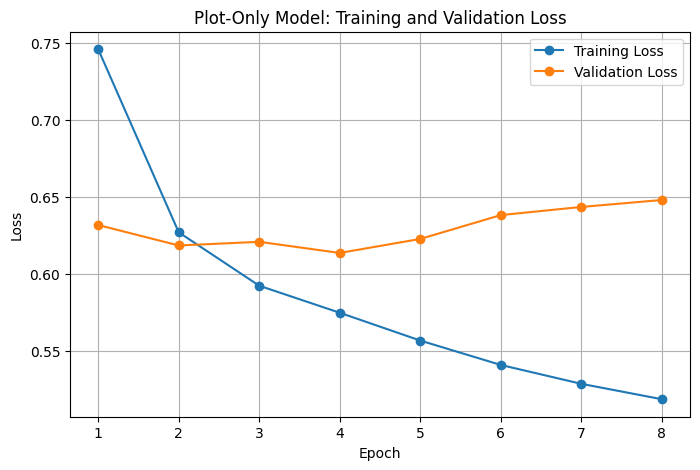

In [23]:
import pandas as pd
import matplotlib.pyplot as plt

# Save training history
text_history_df = pd.DataFrame(text_training_history)

text_history_path = os.path.join(
    RESULTS_DIR, "plot_only_training_history.csv"
)

text_history_df.to_csv(text_history_path, index=False)

print("Training history saved:", text_history_path)

# Plot learning curves
plt.figure(figsize=(8, 5))

plt.plot(
    text_history_df["epoch"],
    text_history_df["training_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    text_history_df["epoch"],
    text_history_df["validation_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Plot-Only Model: Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

2.2.15 – Restore the Best Model Checkpoint

In [24]:
# Load the best saved model
text_model.load_state_dict(
    torch.load(TEXT_CHECKPOINT_PATH, map_location=device)
)

text_model.eval()

print("Best Plot-Only model checkpoint restored.")
print("Best validation loss:", best_val_loss_text)

Best Plot-Only model checkpoint restored.
Best validation loss: 0.6137415487920085


Section 2.2.16 – Plot-Only Model Validation Evaluation

In [25]:
import numpy as np
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    average_precision_score
)

# Ensure the best checkpoint is being used
text_model.eval()

text_val_probabilities = []
text_val_true_labels = []

# Generate predictions without calculating gradients
with torch.no_grad():

    for batch_features, batch_labels in text_val_loader:

        batch_features = batch_features.to(device)

        # Obtain raw model outputs (logits)
        logits = text_model(batch_features)

        # Convert logits into probabilities
        probabilities = torch.sigmoid(logits)

        text_val_probabilities.append(
            probabilities.cpu().numpy()
        )

        text_val_true_labels.append(
            batch_labels.numpy()
        )

# Combine all validation batches
text_val_probabilities = np.concatenate(
    text_val_probabilities, axis=0
)

text_val_true_labels = np.concatenate(
    text_val_true_labels, axis=0
)

# Apply default prediction threshold
TEXT_DEFAULT_THRESHOLD = 0.50

text_val_predictions = (
    text_val_probabilities >= TEXT_DEFAULT_THRESHOLD
).astype(int)

print("Validation probabilities shape:",
      text_val_probabilities.shape)

print("Validation labels shape:",
      text_val_true_labels.shape)

print("Prediction shape:",
      text_val_predictions.shape)

Validation probabilities shape: (3935, 23)
Validation labels shape: (3935, 23)
Prediction shape: (3935, 23)


In [26]:
# Calculate F1 scores
text_micro_f1 = f1_score(
    text_val_true_labels,
    text_val_predictions,
    average="micro",
    zero_division=0
)

text_macro_f1 = f1_score(
    text_val_true_labels,
    text_val_predictions,
    average="macro",
    zero_division=0
)

# Calculate precision and recall
text_micro_precision = precision_score(
    text_val_true_labels,
    text_val_predictions,
    average="micro",
    zero_division=0
)

text_micro_recall = recall_score(
    text_val_true_labels,
    text_val_predictions,
    average="micro",
    zero_division=0
)

# Calculate average precision using probabilities
text_macro_ap = average_precision_score(
    text_val_true_labels,
    text_val_probabilities,
    average="macro"
)

text_micro_ap = average_precision_score(
    text_val_true_labels,
    text_val_probabilities,
    average="micro"
)

print("PLOT-ONLY MODEL VALIDATION RESULTS")
print("----------------------------------")
print(f"Micro F1:               {text_micro_f1:.4f}")
print(f"Macro F1:               {text_macro_f1:.4f}")
print(f"Micro Precision:        {text_micro_precision:.4f}")
print(f"Micro Recall:           {text_micro_recall:.4f}")
print(f"Macro Average Precision:{text_macro_ap:.4f}")
print(f"Micro Average Precision:{text_micro_ap:.4f}")

PLOT-ONLY MODEL VALIDATION RESULTS
----------------------------------
Micro F1:               0.5446
Macro F1:               0.4802
Micro Precision:        0.4090
Micro Recall:           0.8148
Macro Average Precision:0.6046
Micro Average Precision:0.5852


2.2.17 – Plot-Only Model Threshold Optimisation

In [27]:
from sklearn.metrics import f1_score
import pandas as pd
import numpy as np
import os

# Test different classification thresholds
thresholds = np.arange(0.10, 0.91, 0.05)

text_threshold_results = []

for threshold in thresholds:

    # Convert probabilities into binary predictions
    predictions = (
        text_val_probabilities >= threshold
    ).astype(int)

    # Calculate Micro and Macro F1
    micro_f1 = f1_score(
        text_val_true_labels,
        predictions,
        average="micro",
        zero_division=0
    )

    macro_f1 = f1_score(
        text_val_true_labels,
        predictions,
        average="macro",
        zero_division=0
    )

    text_threshold_results.append({
        "Threshold": round(float(threshold), 2),
        "Micro F1": micro_f1,
        "Macro F1": macro_f1
    })

# Convert results into a DataFrame
text_threshold_df = pd.DataFrame(text_threshold_results)

# Display results
print("PLOT-ONLY MODEL THRESHOLD RESULTS")
display(text_threshold_df.round(4))

# Identify thresholds with the highest scores
best_micro_row = text_threshold_df.loc[
    text_threshold_df["Micro F1"].idxmax()
]

best_macro_row = text_threshold_df.loc[
    text_threshold_df["Macro F1"].idxmax()
]

print("\nBest Micro F1 threshold:",
      best_micro_row["Threshold"])

print("Best Micro F1:",
      round(best_micro_row["Micro F1"], 4))

print("\nBest Macro F1 threshold:",
      best_macro_row["Threshold"])

print("Best Macro F1:",
      round(best_macro_row["Macro F1"], 4))

# Select threshold based on Macro F1
# This gives equal importance to all 23 genres.
TEXT_OPTIMAL_THRESHOLD = float(
    best_macro_row["Threshold"]
)

print("\nSelected Plot-Only threshold:",
      TEXT_OPTIMAL_THRESHOLD)

# Save threshold results and selected threshold
text_threshold_path = os.path.join(
    RESULTS_DIR, "plot_only_threshold_results.csv"
)

text_threshold_df.to_csv(
    text_threshold_path, index=False
)

np.save(
    os.path.join(
        RESULTS_DIR, "plot_optimal_threshold.npy"
    ),
    TEXT_OPTIMAL_THRESHOLD
)

print("\nThreshold results saved successfully.")

PLOT-ONLY MODEL THRESHOLD RESULTS


,Threshold,Micro F1,Macro F1
0,0.10,0.3330,0.2838
1,0.15,0.3730,0.3174
2,0.20,0.4051,0.3450
3,0.25,0.4345,0.3711
4,0.30,0.4616,0.3955
5,0.35,0.4866,0.4193
6,0.40,0.5085,0.4402
7,0.45,0.5279,0.4601
8,0.50,0.5446,0.4802
9,0.55,0.5544,0.4941



Best Micro F1 threshold: 0.7
Best Micro F1: 0.5721

Best Macro F1 threshold: 0.75
Best Macro F1: 0.5391

Selected Plot-Only threshold: 0.75

Threshold results saved successfully.


In [29]:
import os
import numpy as np

DRIVE_DIR = "/content/drive/MyDrive/MM_IMDb_Project"
DATA_DIR = os.path.join(DRIVE_DIR, "data")
RESULTS_DIR = os.path.join(DRIVE_DIR, "results")

# Check saved prepared image features
image_features_path = os.path.join(
    RESULTS_DIR, "prepared_image_features.npz"
)

image_data = np.load(image_features_path)

print("IMAGE FEATURE FILE CONTENTS")
print(image_data.files)

# Check saved dataset splits
splits_path = os.path.join(
    RESULTS_DIR, "dataset_splits.npz"
)

split_data = np.load(splits_path)

print("\nDATASET SPLIT FILE CONTENTS")
print(split_data.files)

# Check saved text embeddings
text_embeddings_path = os.path.join(
    RESULTS_DIR, "distilbert_text_embeddings.npy"
)

text_embeddings = np.load(text_embeddings_path)

print("\nTEXT EMBEDDINGS SHAPE:", text_embeddings.shape)

IMAGE FEATURE FILE CONTENTS
['X_img_train', 'X_img_val', 'X_img_test', 'y_train', 'y_val', 'y_test']

DATASET SPLIT FILE CONTENTS
['train_idx', 'val_idx', 'test_idx', 'random_seed']

TEXT EMBEDDINGS SHAPE: (25959, 768)


Step 1 – Reload the original image features

In [30]:
import joblib
import numpy as np
import os

# Load saved image features
image_data = np.load(
    os.path.join(RESULTS_DIR, "prepared_image_features.npz")
)

X_img_train = image_data["X_img_train"]
X_img_val = image_data["X_img_val"]
X_img_test = image_data["X_img_test"]

y_train = image_data["y_train"]
y_val = image_data["y_val"]
y_test = image_data["y_test"]

# Load the original image scaler
image_scaler_path = os.path.join(
    RESULTS_DIR, "image_feature_scaler.pkl"
)

image_scaler = joblib.load(image_scaler_path)

# Reconstruct scaled image features
X_img_train_scaled = image_scaler.transform(X_img_train)
X_img_val_scaled = image_scaler.transform(X_img_val)
X_img_test_scaled = image_scaler.transform(X_img_test)

print("Image features successfully reconstructed.")
print("Training:", X_img_train_scaled.shape)
print("Validation:", X_img_val_scaled.shape)
print("Testing:", X_img_test_scaled.shape)

Image features successfully reconstructed.
Training: (18146, 4096)
Validation: (3935, 4096)
Testing: (3878, 4096)


Step 2 – Reconstruct the scaled text features

In [31]:
# Load saved text embeddings
text_embeddings = np.load(
    os.path.join(
        RESULTS_DIR, "distilbert_text_embeddings.npy"
    )
)

# Load original dataset split indices
split_data = np.load(
    os.path.join(RESULTS_DIR, "dataset_splits.npz")
)

train_idx = split_data["train_idx"]
val_idx = split_data["val_idx"]
test_idx = split_data["test_idx"]

# Reconstruct text features using the original split
X_text_train = text_embeddings[train_idx]
X_text_val = text_embeddings[val_idx]
X_text_test = text_embeddings[test_idx]

# Load the original text scaler
text_scaler = joblib.load(
    os.path.join(RESULTS_DIR, "text_feature_scaler.pkl")
)

# Transform using the scaler fitted on training data
X_text_train_scaled = text_scaler.transform(X_text_train)
X_text_val_scaled = text_scaler.transform(X_text_val)
X_text_test_scaled = text_scaler.transform(X_text_test)

print("Text features successfully reconstructed.")
print("Training:", X_text_train_scaled.shape)
print("Validation:", X_text_val_scaled.shape)
print("Testing:", X_text_test_scaled.shape)

Text features successfully reconstructed.
Training: (18146, 768)
Validation: (3935, 768)
Testing: (3878, 768)


Step 3 – Verify label alignment

In [32]:
print("Checking label alignment...")

print("Training labels:", y_train.shape)
print("Validation labels:", y_val.shape)
print("Testing labels:", y_test.shape)

assert len(X_img_train_scaled) == len(X_text_train_scaled) == len(y_train)
assert len(X_img_val_scaled) == len(X_text_val_scaled) == len(y_val)
assert len(X_img_test_scaled) == len(X_text_test_scaled) == len(y_test)

print("\nAll modalities and labels are aligned.")

Checking label alignment...
Training labels: (18146, 23)
Validation labels: (3935, 23)
Testing labels: (3878, 23)

All modalities and labels are aligned.


2.2.18 – Prepare Features for Early Fusion

In [33]:
# Combine visual and textual features
X_fusion_train = np.concatenate(
    [X_img_train_scaled, X_text_train_scaled],
    axis=1
)

X_fusion_val = np.concatenate(
    [X_img_val_scaled, X_text_val_scaled],
    axis=1
)

X_fusion_test = np.concatenate(
    [X_img_test_scaled, X_text_test_scaled],
    axis=1
)

# Verify dimensions
print("EARLY FUSION FEATURE SHAPES")
print("---------------------------")

print("Training:", X_fusion_train.shape)
print("Validation:", X_fusion_val.shape)
print("Testing:", X_fusion_test.shape)

print("\nTotal combined features:",
      X_fusion_train.shape[1])

print("\nNaN values:",
      np.isnan(X_fusion_train).sum())

print("Infinite values:",
      np.isinf(X_fusion_train).sum())

EARLY FUSION FEATURE SHAPES
---------------------------
Training: (18146, 4864)
Validation: (3935, 4864)
Testing: (3878, 4864)

Total combined features: 4864

NaN values: 0
Infinite values: 0


Section 2.2.19 – Define the Early Fusion Model

In [34]:
import torch
import torch.nn as nn

class EarlyFusionMLP(nn.Module):

    def __init__(
        self,
        input_size=4864,
        hidden_size=512,
        output_size=23
    ):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(hidden_size, output_size)
        )

    def forward(self, x):
        return self.network(x)


# Initialise model
fusion_model = EarlyFusionMLP().to(device)

# Use class weights calculated from training labels
fusion_pos_weights = torch.tensor(
    (len(y_train) - y_train.sum(axis=0)) /
    y_train.sum(axis=0),
    dtype=torch.float32
).to(device)

# Loss function and optimiser
fusion_criterion = nn.BCEWithLogitsLoss(
    pos_weight=fusion_pos_weights
)

fusion_optimizer = torch.optim.Adam(
    fusion_model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

print("Early Fusion Model:")
print(fusion_model)

print("\nComputing device:", device)
print("Loss function: BCEWithLogitsLoss")
print("Optimiser: Adam")

Early Fusion Model:
EarlyFusionMLP(
  (network): Sequential(
    (0): Linear(in_features=4864, out_features=512, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.4, inplace=False)
    (3): Linear(in_features=512, out_features=23, bias=True)
  )
)

Computing device: cuda
Loss function: BCEWithLogitsLoss
Optimiser: Adam


Section 2.2.20 – Prepare Early Fusion DataLoaders

In [35]:
from torch.utils.data import TensorDataset, DataLoader

# Convert combined features into tensors
X_fusion_train_tensor = torch.tensor(
    X_fusion_train, dtype=torch.float32
)

X_fusion_val_tensor = torch.tensor(
    X_fusion_val, dtype=torch.float32
)

y_fusion_train_tensor = torch.tensor(
    y_train, dtype=torch.float32
)

y_fusion_val_tensor = torch.tensor(
    y_val, dtype=torch.float32
)

# Create datasets
fusion_train_dataset = TensorDataset(
    X_fusion_train_tensor,
    y_fusion_train_tensor
)

fusion_val_dataset = TensorDataset(
    X_fusion_val_tensor,
    y_fusion_val_tensor
)

# Create DataLoaders
BATCH_SIZE_FUSION = 128

fusion_train_loader = DataLoader(
    fusion_train_dataset,
    batch_size=BATCH_SIZE_FUSION,
    shuffle=True
)

fusion_val_loader = DataLoader(
    fusion_val_dataset,
    batch_size=BATCH_SIZE_FUSION,
    shuffle=False
)

print("Training samples:", len(fusion_train_dataset))
print("Validation samples:", len(fusion_val_dataset))
print("Training batches:", len(fusion_train_loader))
print("Validation batches:", len(fusion_val_loader))
print("Batch size:", BATCH_SIZE_FUSION)

Training samples: 18146
Validation samples: 3935
Training batches: 142
Validation batches: 31
Batch size: 128


Section 2.2.21 – Train the Early Fusion Model

In [36]:
# Training configuration
EPOCHS_FUSION = 20
PATIENCE_FUSION = 4

best_val_loss_fusion = float("inf")
epochs_without_improvement_fusion = 0

fusion_training_history = []

FUSION_CHECKPOINT_PATH = os.path.join(
    RESULTS_DIR, "early_fusion_best_model.pth"
)

# Training loop
for epoch in range(EPOCHS_FUSION):

    fusion_model.train()
    train_loss = 0.0

    for batch_features, batch_labels in fusion_train_loader:

        batch_features = batch_features.to(device)
        batch_labels = batch_labels.to(device)

        fusion_optimizer.zero_grad()

        outputs = fusion_model(batch_features)
        loss = fusion_criterion(outputs, batch_labels)

        loss.backward()
        fusion_optimizer.step()

        train_loss += loss.item()

    train_loss /= len(fusion_train_loader)

    # Validation
    fusion_model.eval()
    val_loss = 0.0

    with torch.no_grad():

        for batch_features, batch_labels in fusion_val_loader:

            batch_features = batch_features.to(device)
            batch_labels = batch_labels.to(device)

            outputs = fusion_model(batch_features)
            loss = fusion_criterion(outputs, batch_labels)

            val_loss += loss.item()

    val_loss /= len(fusion_val_loader)

    fusion_training_history.append({
        "epoch": epoch + 1,
        "training_loss": train_loss,
        "validation_loss": val_loss
    })

    print(
        f"Epoch [{epoch + 1}/{EPOCHS_FUSION}] "
        f"Training Loss: {train_loss:.4f} | "
        f"Validation Loss: {val_loss:.4f}"
    )

    # Save best model
    if val_loss < best_val_loss_fusion:

        best_val_loss_fusion = val_loss
        epochs_without_improvement_fusion = 0

        torch.save(
            fusion_model.state_dict(),
            FUSION_CHECKPOINT_PATH
        )

        print("Best model checkpoint saved.")

    else:
        epochs_without_improvement_fusion += 1

    # Early stopping
    if epochs_without_improvement_fusion >= PATIENCE_FUSION:

        print("Early stopping triggered.")
        break

print("\nEarly Fusion Training Completed.")
print("Best validation loss:", best_val_loss_fusion)
print("Checkpoint:", FUSION_CHECKPOINT_PATH)

Epoch [1/20] Training Loss: 0.7928 | Validation Loss: 0.6735
Best model checkpoint saved.
Epoch [2/20] Training Loss: 0.5616 | Validation Loss: 0.6926
Epoch [3/20] Training Loss: 0.4772 | Validation Loss: 0.7119
Epoch [4/20] Training Loss: 0.4231 | Validation Loss: 0.7580
Epoch [5/20] Training Loss: 0.3902 | Validation Loss: 0.8128
Early stopping triggered.

Early Fusion Training Completed.
Best validation loss: 0.6734655461003703
Checkpoint: /content/drive/MyDrive/MM_IMDb_Project/results/early_fusion_best_model.pth


2.2.22 – Save Training History and Plot Learning Curves

Training history saved: /content/drive/MyDrive/MM_IMDb_Project/results/early_fusion_training_history.csv


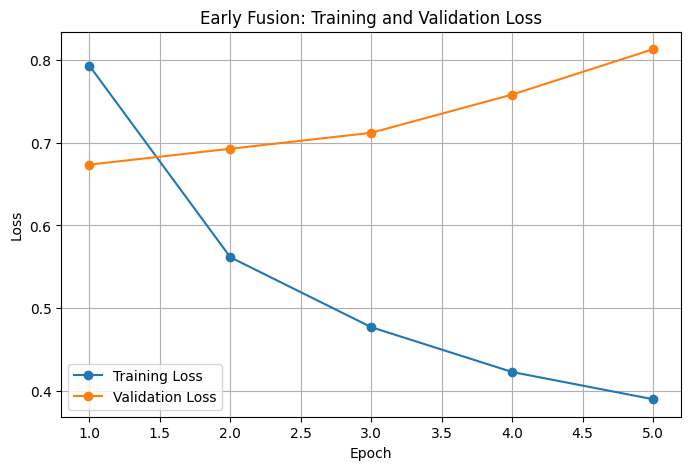

In [37]:
import pandas as pd
import matplotlib.pyplot as plt

# Save training history
fusion_history_df = pd.DataFrame(
    fusion_training_history
)

fusion_history_path = os.path.join(
    RESULTS_DIR, "early_fusion_training_history.csv"
)

fusion_history_df.to_csv(
    fusion_history_path, index=False
)

print("Training history saved:", fusion_history_path)

# Plot learning curves
plt.figure(figsize=(8, 5))

plt.plot(
    fusion_history_df["epoch"],
    fusion_history_df["training_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    fusion_history_df["epoch"],
    fusion_history_df["validation_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Early Fusion: Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

2.2.23 – Restore the Best Early Fusion Checkpoint

In [38]:
fusion_model.load_state_dict(
    torch.load(
        FUSION_CHECKPOINT_PATH,
        map_location=device
    )
)

fusion_model.eval()

print("Best Early Fusion checkpoint restored.")
print("Best validation loss:", best_val_loss_fusion)

Best Early Fusion checkpoint restored.
Best validation loss: 0.6734655461003703


Section 2.2.24 – Early Fusion Validation Evaluation

In [39]:
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    average_precision_score
)
import numpy as np

# Restore evaluation mode
fusion_model.eval()

fusion_val_probabilities = []
fusion_val_true_labels = []

# Generate predictions
with torch.no_grad():

    for batch_features, batch_labels in fusion_val_loader:

        batch_features = batch_features.to(device)

        logits = fusion_model(batch_features)

        probabilities = torch.sigmoid(logits)

        fusion_val_probabilities.append(
            probabilities.cpu().numpy()
        )

        fusion_val_true_labels.append(
            batch_labels.numpy()
        )

# Combine batches
fusion_val_probabilities = np.concatenate(
    fusion_val_probabilities, axis=0
)

fusion_val_true_labels = np.concatenate(
    fusion_val_true_labels, axis=0
)

# Apply default threshold
FUSION_DEFAULT_THRESHOLD = 0.50

fusion_val_predictions = (
    fusion_val_probabilities >= FUSION_DEFAULT_THRESHOLD
).astype(int)

print("Validation probabilities:",
      fusion_val_probabilities.shape)

print("Validation labels:",
      fusion_val_true_labels.shape)

print("Validation predictions:",
      fusion_val_predictions.shape)

Validation probabilities: (3935, 23)
Validation labels: (3935, 23)
Validation predictions: (3935, 23)


In [40]:
# Calculate classification metrics
fusion_micro_f1 = f1_score(
    fusion_val_true_labels,
    fusion_val_predictions,
    average="micro",
    zero_division=0
)

fusion_macro_f1 = f1_score(
    fusion_val_true_labels,
    fusion_val_predictions,
    average="macro",
    zero_division=0
)

fusion_micro_precision = precision_score(
    fusion_val_true_labels,
    fusion_val_predictions,
    average="micro",
    zero_division=0
)

fusion_micro_recall = recall_score(
    fusion_val_true_labels,
    fusion_val_predictions,
    average="micro",
    zero_division=0
)

fusion_macro_ap = average_precision_score(
    fusion_val_true_labels,
    fusion_val_probabilities,
    average="macro"
)

fusion_micro_ap = average_precision_score(
    fusion_val_true_labels,
    fusion_val_probabilities,
    average="micro"
)

print("EARLY FUSION MODEL VALIDATION RESULTS")
print("-------------------------------------")
print(f"Micro F1:                {fusion_micro_f1:.4f}")
print(f"Macro F1:                {fusion_macro_f1:.4f}")
print(f"Micro Precision:         {fusion_micro_precision:.4f}")
print(f"Micro Recall:            {fusion_micro_recall:.4f}")
print(f"Macro Average Precision: {fusion_macro_ap:.4f}")
print(f"Micro Average Precision: {fusion_micro_ap:.4f}")

EARLY FUSION MODEL VALIDATION RESULTS
-------------------------------------
Micro F1:                0.5100
Macro F1:                0.4471
Micro Precision:         0.3784
Micro Recall:            0.7820
Macro Average Precision: 0.5704
Micro Average Precision: 0.5303


Section 2.2.25 – Early Fusion Threshold Optimisation

In [41]:
# Test thresholds from 0.10 to 0.90
fusion_thresholds = np.arange(0.10, 0.91, 0.05)

fusion_threshold_results = []

for threshold in fusion_thresholds:

    predictions = (
        fusion_val_probabilities >= threshold
    ).astype(int)

    micro_f1 = f1_score(
        fusion_val_true_labels,
        predictions,
        average="micro",
        zero_division=0
    )

    macro_f1 = f1_score(
        fusion_val_true_labels,
        predictions,
        average="macro",
        zero_division=0
    )

    fusion_threshold_results.append({
        "Threshold": round(float(threshold), 2),
        "Micro F1": micro_f1,
        "Macro F1": macro_f1
    })

# Create results table
fusion_threshold_df = pd.DataFrame(
    fusion_threshold_results
)

display(fusion_threshold_df.round(4))

# Identify best thresholds
best_fusion_micro = fusion_threshold_df.loc[
    fusion_threshold_df["Micro F1"].idxmax()
]

best_fusion_macro = fusion_threshold_df.loc[
    fusion_threshold_df["Macro F1"].idxmax()
]

print("\nBest Micro F1 threshold:",
      best_fusion_micro["Threshold"])

print("Best Micro F1:",
      round(best_fusion_micro["Micro F1"], 4))

print("\nBest Macro F1 threshold:",
      best_fusion_macro["Threshold"])

print("Best Macro F1:",
      round(best_fusion_macro["Macro F1"], 4))

# Select threshold based on Macro F1
FUSION_OPTIMAL_THRESHOLD = float(
    best_fusion_macro["Threshold"]
)

print("\nSelected Early Fusion threshold:",
      FUSION_OPTIMAL_THRESHOLD)

# Save threshold results
fusion_threshold_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "early_fusion_threshold_results.csv"
    ),
    index=False
)

np.save(
    os.path.join(
        RESULTS_DIR,
        "early_fusion_optimal_threshold.npy"
    ),
    FUSION_OPTIMAL_THRESHOLD
)

print("\nThreshold results saved successfully.")

,Threshold,Micro F1,Macro F1
0,0.10,0.3291,0.2795
1,0.15,0.3651,0.3099
2,0.20,0.3948,0.3359
3,0.25,0.4205,0.3581
4,0.30,0.4434,0.3792
5,0.35,0.4642,0.3987
6,0.40,0.4827,0.4167
7,0.45,0.4973,0.4321
8,0.50,0.5100,0.4471
9,0.55,0.5227,0.4621



Best Micro F1 threshold: 0.65
Best Micro F1: 0.5369

Best Macro F1 threshold: 0.8
Best Macro F1: 0.5025

Selected Early Fusion threshold: 0.8

Threshold results saved successfully.


Section 2.2.26 – Prepare Late Fusion

Step 1 – Correct the Poster-Only checkpoint loading

In [43]:
# Load Poster-Only checkpoint
poster_checkpoint = torch.load(
    POSTER_CHECKPOINT_PATH,
    map_location=device
)

poster_model_late.load_state_dict(
    poster_checkpoint["model_state_dict"]
)

print("Poster-Only checkpoint restored successfully.")
print("Best epoch:", poster_checkpoint["epoch"])
print("Best validation loss:",
      poster_checkpoint["best_val_loss"])

Poster-Only checkpoint restored successfully.
Best epoch: 1
Best validation loss: 1.0591924248203155


Step 2 – Load the Plot-Only checkpoint

In [44]:
# Load Plot-Only checkpoint
plot_checkpoint = torch.load(
    PLOT_CHECKPOINT_PATH,
    map_location=device
)

if "model_state_dict" in plot_checkpoint:
    plot_model_late.load_state_dict(
        plot_checkpoint["model_state_dict"]
    )
else:
    plot_model_late.load_state_dict(plot_checkpoint)

print("Plot-Only checkpoint restored successfully.")

Plot-Only checkpoint restored successfully.


Step 3 – Verify both models

In [45]:
poster_model_late.eval()
plot_model_late.eval()

print("\nBoth unimodal models are ready for Late Fusion.")


Both unimodal models are ready for Late Fusion.


Section 2.2.26 – Step 2: Generate validation probabilities

In [46]:
# Prepare validation feature tensors
poster_val_tensor = torch.tensor(
    X_img_val_scaled,
    dtype=torch.float32
)

plot_val_tensor = torch.tensor(
    X_text_val_scaled,
    dtype=torch.float32
)

# Generate predictions from both models
with torch.no_grad():

    poster_logits_late = poster_model_late(
        poster_val_tensor.to(device)
    )

    plot_logits_late = plot_model_late(
        plot_val_tensor.to(device)
    )

    # Convert logits into probabilities
    poster_val_probabilities_late = torch.sigmoid(
        poster_logits_late
    ).cpu().numpy()

    plot_val_probabilities_late = torch.sigmoid(
        plot_logits_late
    ).cpu().numpy()

# Verify prediction dimensions
print("Poster probabilities:",
      poster_val_probabilities_late.shape)

print("Plot probabilities:",
      plot_val_probabilities_late.shape)

print("Validation labels:", y_val.shape)

Poster probabilities: (3935, 23)
Plot probabilities: (3935, 23)
Validation labels: (3935, 23)


Section 2.2.27 – Late Fusion Weight Optimisation

Step 1 – Test different fusion weights

In [47]:
# Define fusion weights
alpha_values = np.arange(0.0, 1.01, 0.05)

late_fusion_results = []

for alpha in alpha_values:

    # Combine poster and plot probabilities
    combined_probabilities = (
        alpha * poster_val_probabilities_late
        + (1 - alpha) * plot_val_probabilities_late
    )

    # Use threshold 0.50 for initial weight comparison
    combined_predictions = (
        combined_probabilities >= 0.50
    ).astype(int)

    micro_f1 = f1_score(
        y_val,
        combined_predictions,
        average="micro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_val,
        combined_predictions,
        average="macro",
        zero_division=0
    )

    late_fusion_results.append({
        "Alpha": round(float(alpha), 2),
        "Micro F1": micro_f1,
        "Macro F1": macro_f1
    })

# Display results
late_fusion_df = pd.DataFrame(late_fusion_results)

display(late_fusion_df.round(4))

# Identify best alpha using Macro F1
best_late_fusion_row = late_fusion_df.loc[
    late_fusion_df["Macro F1"].idxmax()
]

BEST_ALPHA = float(best_late_fusion_row["Alpha"])

print("\nBest fusion weight (Alpha):", BEST_ALPHA)
print("Best Macro F1:",
      round(best_late_fusion_row["Macro F1"], 4))

print("Corresponding Micro F1:",
      round(best_late_fusion_row["Micro F1"], 4))

,Alpha,Micro F1,Macro F1
0,0.00,0.5446,0.4802
1,0.05,0.5461,0.4814
2,0.10,0.5475,0.4828
3,0.15,0.5486,0.4837
4,0.20,0.5503,0.4844
5,0.25,0.5525,0.4861
6,0.30,0.5529,0.4860
7,0.35,0.5543,0.4875
8,0.40,0.5527,0.4862
9,0.45,0.5475,0.4817



Best fusion weight (Alpha): 0.35
Best Macro F1: 0.4875
Corresponding Micro F1: 0.5543


Step 2 – Save the fusion weight

In [48]:
np.save(
    os.path.join(RESULTS_DIR, "late_fusion_best_alpha.npy"),
    BEST_ALPHA
)

print("Best Late Fusion weight saved:", BEST_ALPHA)

Best Late Fusion weight saved: 0.35


Section 2.2.28 – Late Fusion Threshold Optimisation

Step 1 – Generate combined probabilities and optimise threshold

In [49]:
# Load selected fusion weight
BEST_ALPHA = float(
    np.load(
        os.path.join(RESULTS_DIR, "late_fusion_best_alpha.npy")
    )
)

# Combine poster and plot probabilities
late_fusion_val_probabilities = (
    BEST_ALPHA * poster_val_probabilities_late
    + (1 - BEST_ALPHA) * plot_val_probabilities_late
)

# Test classification thresholds
late_thresholds = np.arange(0.10, 0.91, 0.05)

late_threshold_results = []

for threshold in late_thresholds:

    predictions = (
        late_fusion_val_probabilities >= threshold
    ).astype(int)

    micro_f1 = f1_score(
        y_val,
        predictions,
        average="micro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_val,
        predictions,
        average="macro",
        zero_division=0
    )

    late_threshold_results.append({
        "Threshold": round(float(threshold), 2),
        "Micro F1": micro_f1,
        "Macro F1": macro_f1
    })

# Create results table
late_threshold_df = pd.DataFrame(
    late_threshold_results
)

display(late_threshold_df.round(4))

# Find optimal thresholds
best_late_micro = late_threshold_df.loc[
    late_threshold_df["Micro F1"].idxmax()
]

best_late_macro = late_threshold_df.loc[
    late_threshold_df["Macro F1"].idxmax()
]

print("\nBest Micro F1 threshold:",
      best_late_micro["Threshold"])

print("Best Micro F1:",
      round(best_late_micro["Micro F1"], 4))

print("\nBest Macro F1 threshold:",
      best_late_macro["Threshold"])

print("Best Macro F1:",
      round(best_late_macro["Macro F1"], 4))

# Select threshold based on Macro F1
LATE_OPTIMAL_THRESHOLD = float(
    best_late_macro["Threshold"]
)

print("\nSelected Late Fusion threshold:",
      LATE_OPTIMAL_THRESHOLD)

,Threshold,Micro F1,Macro F1
0,0.10,0.2326,0.2014
1,0.15,0.2615,0.2237
2,0.20,0.2990,0.2532
3,0.25,0.3447,0.2904
4,0.30,0.3983,0.3360
5,0.35,0.4517,0.3859
6,0.40,0.4925,0.4241
7,0.45,0.5273,0.4580
8,0.50,0.5543,0.4875
9,0.55,0.5741,0.5127



Best Micro F1 threshold: 0.65
Best Micro F1: 0.5916

Best Macro F1 threshold: 0.7
Best Macro F1: 0.5577

Selected Late Fusion threshold: 0.7


Step 2 – Save the results

In [50]:
# Save threshold results
late_threshold_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "late_fusion_threshold_results.csv"
    ),
    index=False
)

np.save(
    os.path.join(
        RESULTS_DIR,
        "late_fusion_optimal_threshold.npy"
    ),
    LATE_OPTIMAL_THRESHOLD
)

print("Late Fusion threshold results saved.")
print("Selected alpha:", BEST_ALPHA)
print("Selected threshold:", LATE_OPTIMAL_THRESHOLD)

Late Fusion threshold results saved.
Selected alpha: 0.35
Selected threshold: 0.7


Section 2.2.29 – Final Test Set Evaluation

Step 1 – Generate test predictions

In [51]:
# Prepare test feature tensors
poster_test_tensor = torch.tensor(
    X_img_test_scaled, dtype=torch.float32
)

plot_test_tensor = torch.tensor(
    X_text_test_scaled, dtype=torch.float32
)

fusion_test_tensor = torch.tensor(
    X_fusion_test, dtype=torch.float32
)

# Set all models to evaluation mode
poster_model_late.eval()
plot_model_late.eval()
fusion_model.eval()

# Generate test probabilities
with torch.no_grad():

    poster_test_probabilities = torch.sigmoid(
        poster_model_late(poster_test_tensor.to(device))
    ).cpu().numpy()

    plot_test_probabilities = torch.sigmoid(
        plot_model_late(plot_test_tensor.to(device))
    ).cpu().numpy()

    fusion_test_probabilities = torch.sigmoid(
        fusion_model(fusion_test_tensor.to(device))
    ).cpu().numpy()

# Late Fusion using validation-selected alpha
late_test_probabilities = (
    BEST_ALPHA * poster_test_probabilities
    + (1 - BEST_ALPHA) * plot_test_probabilities
)

print("POSTER:", poster_test_probabilities.shape)
print("PLOT:", plot_test_probabilities.shape)
print("EARLY FUSION:", fusion_test_probabilities.shape)
print("LATE FUSION:", late_test_probabilities.shape)
print("Test labels:", y_test.shape)

POSTER: (3878, 23)
PLOT: (3878, 23)
EARLY FUSION: (3878, 23)
LATE FUSION: (3878, 23)
Test labels: (3878, 23)


Step 2 – Calculate final test metrics

In [52]:
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    average_precision_score,
    hamming_loss
)

# Model probabilities and selected validation thresholds
test_models = {
    "Poster-Only": (
        poster_test_probabilities,
        0.60
    ),
    "Plot-Only": (
        plot_test_probabilities,
        0.75
    ),
    "Early Fusion": (
        fusion_test_probabilities,
        0.80
    ),
    "Late Fusion": (
        late_test_probabilities,
        0.70
    )
}

test_results = []

for model_name, (probabilities, threshold) in test_models.items():

    predictions = (
        probabilities >= threshold
    ).astype(int)

    test_results.append({
        "Model": model_name,
        "Threshold": threshold,
        "Micro F1": f1_score(
            y_test, predictions,
            average="micro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, predictions,
            average="macro", zero_division=0
        ),
        "Micro Precision": precision_score(
            y_test, predictions,
            average="micro", zero_division=0
        ),
        "Micro Recall": recall_score(
            y_test, predictions,
            average="micro", zero_division=0
        ),
        "Macro AP": average_precision_score(
            y_test, probabilities,
            average="macro"
        ),
        "Micro AP": average_precision_score(
            y_test, probabilities,
            average="micro"
        ),
        "Hamming Loss": hamming_loss(
            y_test, predictions
        )
    })

# Create final comparison table
test_results_df = pd.DataFrame(test_results)

print("FINAL TEST SET PERFORMANCE COMPARISON")
display(test_results_df.round(4))

FINAL TEST SET PERFORMANCE COMPARISON


,Model,Threshold,Micro F1,Macro F1,Micro Precision,Micro Recall,Macro AP,Micro AP,Hamming Loss
0,Poster-Only,0.60,0.3079,0.2771,0.2177,0.5259,0.2881,0.2412,0.2565
1,Plot-Only,0.75,0.5604,0.5346,0.5476,0.5739,0.6055,0.5862,0.0977
2,Early Fusion,0.80,0.5128,0.4990,0.5303,0.4964,0.5705,0.5338,0.1023
3,Late Fusion,0.70,0.5663,0.5506,0.5930,0.5418,0.5973,0.5920,0.0901


Step 3 – Save the final evaluation results

In [53]:
test_results_path = os.path.join(
    RESULTS_DIR,
    "final_test_results.csv"
)

test_results_df.to_csv(
    test_results_path,
    index=False
)

print("Final test results saved:")
print(test_results_path)

Final test results saved:
/content/drive/MyDrive/MM_IMDb_Project/results/final_test_results.csv


Model comparison visualisations

Section 2.2.30 – Visualise Final Test Performance

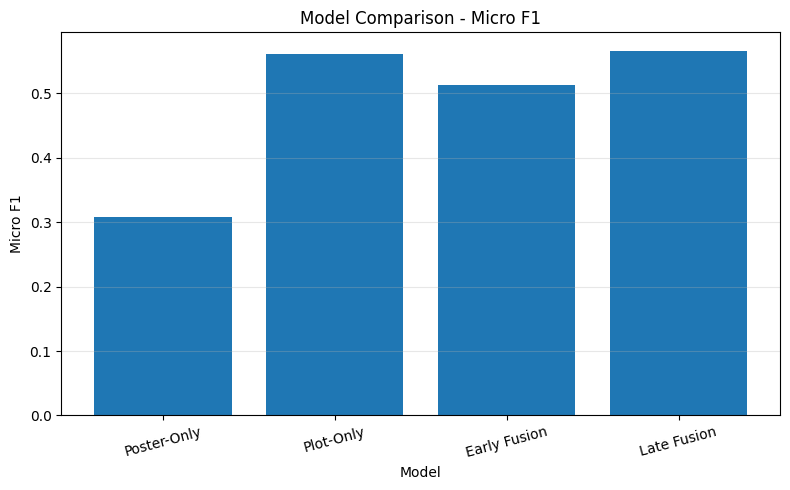

Saved: /content/drive/MyDrive/MM_IMDb_Project/results/test_comparison_micro_f1.png


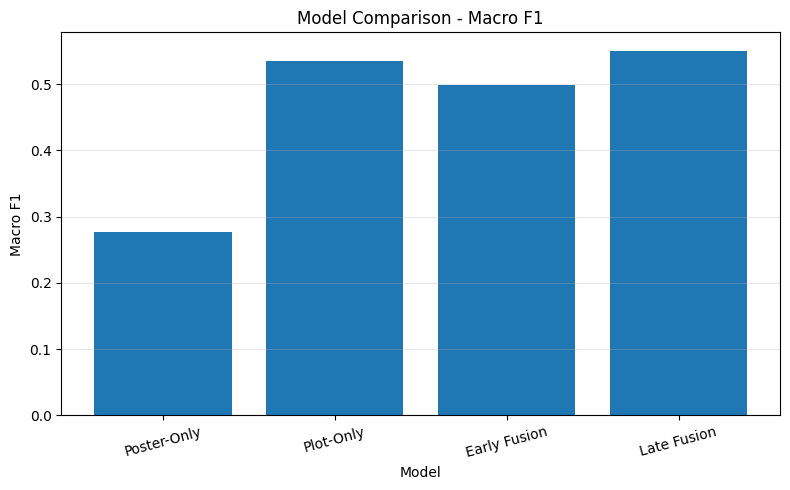

Saved: /content/drive/MyDrive/MM_IMDb_Project/results/test_comparison_macro_f1.png


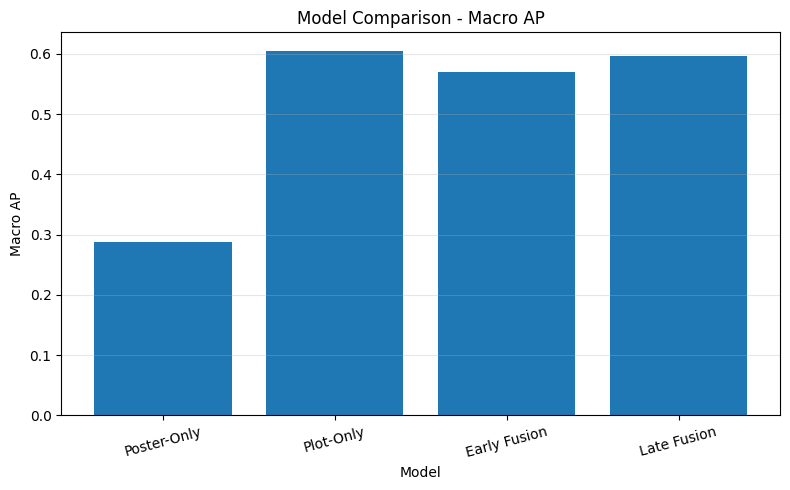

Saved: /content/drive/MyDrive/MM_IMDb_Project/results/test_comparison_macro_ap.png


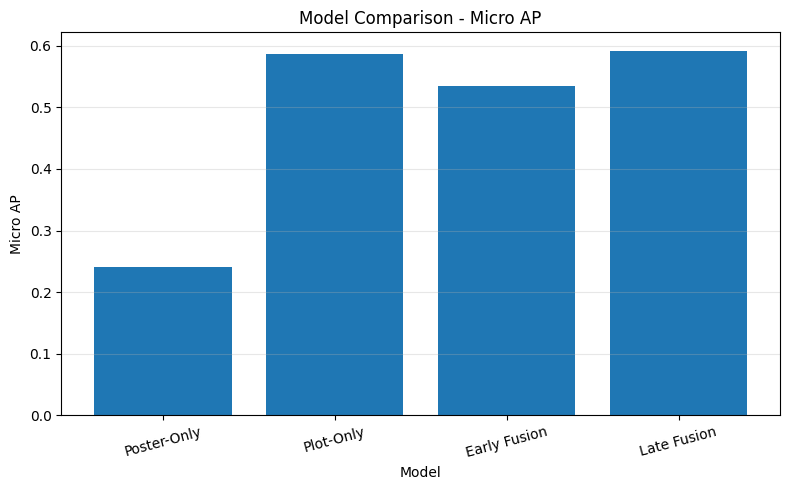

Saved: /content/drive/MyDrive/MM_IMDb_Project/results/test_comparison_micro_ap.png


In [54]:
import matplotlib.pyplot as plt
import numpy as np

# Metrics to compare
metrics_to_plot = [
    "Micro F1",
    "Macro F1",
    "Macro AP",
    "Micro AP"
]

# Create individual comparison charts
for metric in metrics_to_plot:

    plt.figure(figsize=(8, 5))

    plt.bar(
        test_results_df["Model"],
        test_results_df[metric]
    )

    plt.title(f"Model Comparison - {metric}")
    plt.xlabel("Model")
    plt.ylabel(metric)
    plt.xticks(rotation=15)
    plt.grid(axis="y", alpha=0.3)

    plt.tight_layout()

    # Save figure
    figure_path = os.path.join(
        RESULTS_DIR,
        f"test_comparison_{metric.lower().replace(' ', '_')}.png"
    )

    plt.savefig(figure_path, dpi=300)
    plt.show()

    print("Saved:", figure_path)

Verify the genre-label order

In [55]:
# Inspect metadata and HDF5 attributes for genre/label information

print("Metadata keys:")
print(metadata.keys())

with h5py.File(HDF5_PATH, "r") as f:
    print("\nHDF5 attributes:")
    for key, value in f.attrs.items():
        print(key, ":", value)

    print("\nGenre dataset attributes:")
    for key, value in f["genres"].attrs.items():
        print(key, ":", value)

Metadata keys:
dict_keys(['lookup', 'vocab_size', 'word_to_ix', 'ix_to_word'])

HDF5 attributes:
split : [(b'train', b'features',     0, 15552, <HDF5 object reference (null)>,  True, b'.')
 (b'train', b'genres',     0, 15552, <HDF5 object reference (null)>,  True, b'.')
 (b'train', b'images',     0, 15552, <HDF5 object reference (null)>,  True, b'.')
 (b'train', b'imdb_ids',     0, 15552, <HDF5 object reference (null)>,  True, b'.')
 (b'train', b'sequences',     0, 15552, <HDF5 object reference (null)>,  True, b'.')
 (b'train', b'three_grams',     0, 15552, <HDF5 object reference (null)>,  True, b'.')
 (b'train', b'vgg_features',     0, 15552, <HDF5 object reference (null)>,  True, b'.')
 (b'train', b'word_grams',     0, 15552, <HDF5 object reference (null)>,  True, b'.')
 (b'dev', b'features', 15552, 18160, <HDF5 object reference (null)>,  True, b'.')
 (b'dev', b'genres', 15552, 18160, <HDF5 object reference (null)>,  True, b'.')
 (b'dev', b'images', 15552, 18160, <HDF5 object referen

Per-genre performance comparison

In [58]:
# Find all existing test probability and prediction variables

# Safely identify existing test probability variables

for name, value in list(globals().items()):
    if "test" in name.lower() and (
        "prob" in name.lower() or "pred" in name.lower()
    ):
        if hasattr(value, "shape"):
            print(f"{name}: {value.shape}")

poster_test_probabilities: (3878, 23)
plot_test_probabilities: (3878, 23)
fusion_test_probabilities: (3878, 23)
late_test_probabilities: (3878, 23)


In [59]:
# ============================================================
# PER-GENRE PERFORMANCE EVALUATION
# ============================================================

import pandas as pd
import numpy as np
from sklearn.metrics import f1_score, average_precision_score

# Verified genre order
genre_names = [
    "Drama", "Comedy", "Romance", "Thriller", "Crime",
    "Action", "Adventure", "Horror", "Documentary", "Mystery",
    "Sci-Fi", "Fantasy", "Family", "Biography", "War",
    "History", "Music", "Animation", "Musical", "Western",
    "Sport", "Short", "Film-Noir"
]

# Existing test probabilities
model_probabilities = {
    "Poster-Only": poster_test_probabilities,
    "Plot-Only": plot_test_probabilities,
    "Early Fusion": fusion_test_probabilities,
    "Late Fusion": late_test_probabilities
}

# Thresholds selected using validation data
model_thresholds = {
    "Poster-Only": 0.60,
    "Plot-Only": 0.75,
    "Early Fusion": 0.80,
    "Late Fusion": 0.70
}

per_genre_results = []

for model_name, probabilities in model_probabilities.items():

    threshold = model_thresholds[model_name]
    predictions = (probabilities >= threshold).astype(int)

    for i, genre in enumerate(genre_names):

        f1 = f1_score(
            y_test[:, i],
            predictions[:, i],
            zero_division=0
        )

        ap = average_precision_score(
            y_test[:, i],
            probabilities[:, i]
        )

        per_genre_results.append({
            "Model": model_name,
            "Genre": genre,
            "F1 Score": f1,
            "Average Precision": ap
        })

# Create DataFrame
per_genre_df = pd.DataFrame(per_genre_results)

# Save results
per_genre_path = os.path.join(
    RESULTS_DIR,
    "per_genre_performance.csv"
)

per_genre_df.to_csv(per_genre_path, index=False)

print("Per-genre evaluation completed!")
print("Total rows:", len(per_genre_df))
print("Saved to:", per_genre_path)

display(per_genre_df.head(10))

Per-genre evaluation completed!
Total rows: 92
Saved to: /content/drive/MyDrive/MM_IMDb_Project/results/per_genre_performance.csv


,Model,Genre,F1 Score,Average Precision
0,Poster-Only,Drama,0.571671,0.697257
1,Poster-Only,Comedy,0.579887,0.644388
2,Poster-Only,Romance,0.412804,0.372085
3,Poster-Only,Thriller,0.418284,0.406214
4,Poster-Only,Crime,0.328748,0.278627
5,Poster-Only,Action,0.410830,0.387160
6,Poster-Only,Adventure,0.355357,0.296474
7,Poster-Only,Horror,0.426901,0.418408
8,Poster-Only,Documentary,0.243930,0.191220
9,Poster-Only,Mystery,0.198077,0.147356


Compare all four models by genre

In [60]:
# ============================================================
# PER-GENRE MODEL COMPARISON
# ============================================================

# Compare F1 scores across all four models
genre_f1_comparison = per_genre_df.pivot(
    index="Genre",
    columns="Model",
    values="F1 Score"
)

# Compare Average Precision across all four models
genre_ap_comparison = per_genre_df.pivot(
    index="Genre",
    columns="Model",
    values="Average Precision"
)

# Display results
print("F1-SCORE COMPARISON BY GENRE")
display(genre_f1_comparison.round(4))

print("AVERAGE PRECISION COMPARISON BY GENRE")
display(genre_ap_comparison.round(4))

# Save comparison tables
genre_f1_comparison.to_csv(
    os.path.join(RESULTS_DIR, "genre_f1_comparison.csv")
)

genre_ap_comparison.to_csv(
    os.path.join(RESULTS_DIR, "genre_ap_comparison.csv")
)

F1-SCORE COMPARISON BY GENRE


Model,Early Fusion,Late Fusion,Plot-Only,Poster-Only
Genre,,,,
Action,0.6145,0.6424,0.6259,0.4108
Adventure,0.5516,0.5605,0.6036,0.3554
Animation,0.6507,0.5918,0.4660,0.3361
Biography,0.4127,0.4087,0.4308,0.1128
Comedy,0.5835,0.6006,0.5998,0.5799
Crime,0.5851,0.6460,0.6406,0.3287
Documentary,0.7381,0.7903,0.7753,0.2439
Drama,0.4494,0.5485,0.5519,0.5717
Family,0.5499,0.5544,0.5107,0.3187


AVERAGE PRECISION COMPARISON BY GENRE


Model,Early Fusion,Late Fusion,Plot-Only,Poster-Only
Genre,,,,
Action,0.6675,0.6816,0.6742,0.3872
Adventure,0.5649,0.5902,0.6266,0.2965
Animation,0.7026,0.6998,0.5178,0.6285
Biography,0.4152,0.4135,0.4428,0.0858
Comedy,0.7735,0.7842,0.7489,0.6444
Crime,0.6254,0.6730,0.6871,0.2786
Documentary,0.8292,0.8327,0.8701,0.1912
Drama,0.8128,0.8346,0.8270,0.6973
Family,0.6059,0.6358,0.5971,0.4185


Visualise per-genre performance

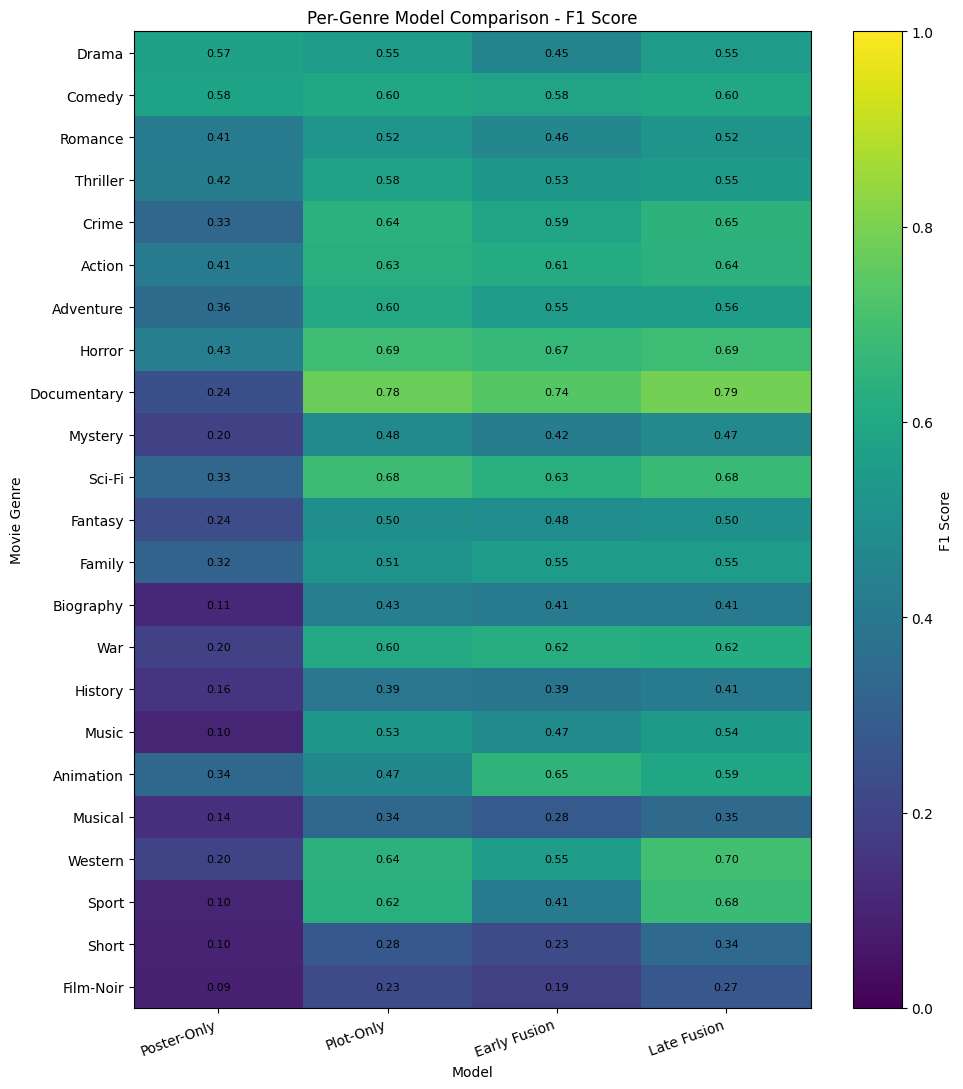

Saved: /content/drive/MyDrive/MM_IMDb_Project/results/per_genre_f1_heatmap.png


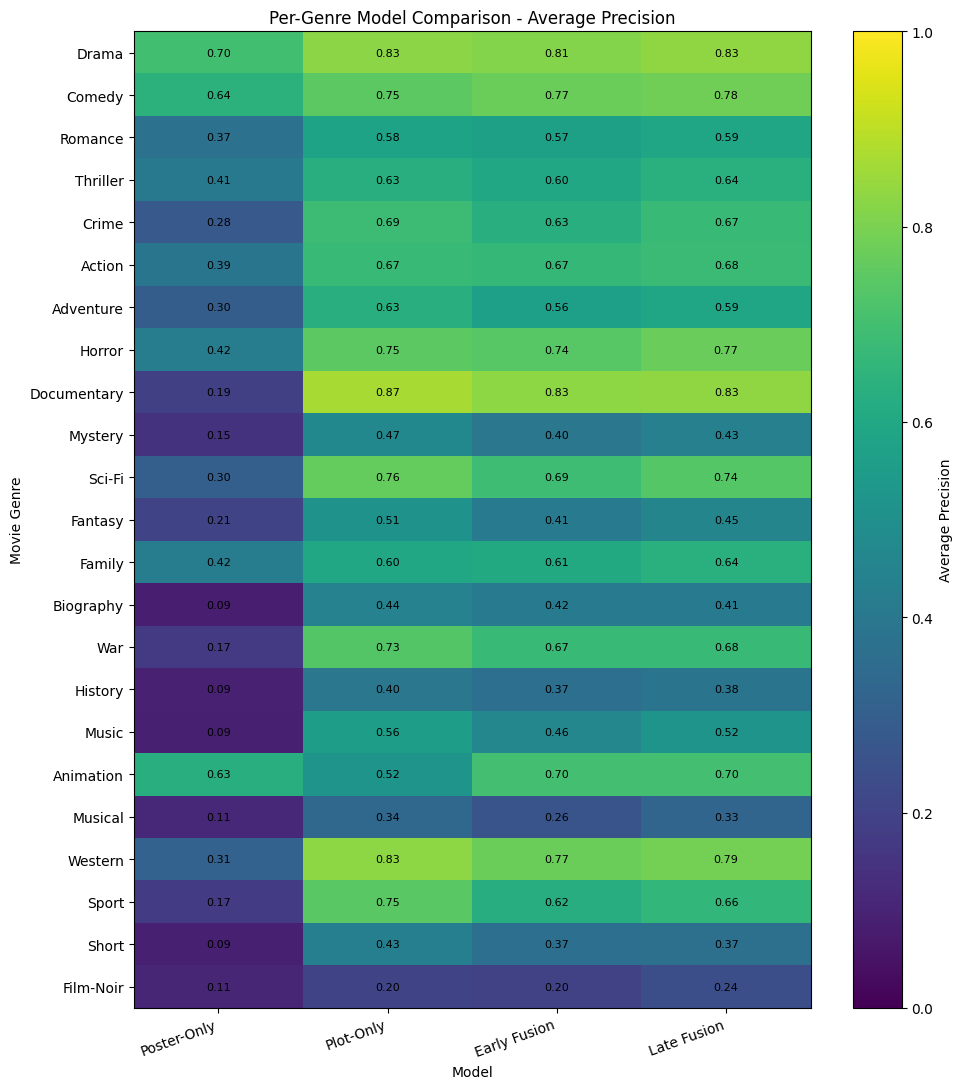

Saved: /content/drive/MyDrive/MM_IMDb_Project/results/per_genre_ap_heatmap.png


In [61]:
# ============================================================
# PER-GENRE PERFORMANCE HEATMAPS
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import os

# Consistent model order
model_order = [
    "Poster-Only",
    "Plot-Only",
    "Early Fusion",
    "Late Fusion"
]

# Consistent genre order
genre_order = genre_names

# Prepare both matrices
f1_matrix = genre_f1_comparison[model_order].loc[genre_order]
ap_matrix = genre_ap_comparison[model_order].loc[genre_order]

# Plot F1-score heatmap
for matrix, metric, filename in [
    (f1_matrix, "F1 Score", "per_genre_f1_heatmap.png"),
    (ap_matrix, "Average Precision", "per_genre_ap_heatmap.png")
]:

    fig, ax = plt.subplots(figsize=(10, 11))

    im = ax.imshow(
        matrix.values,
        aspect="auto",
        vmin=0,
        vmax=1
    )

    ax.set_xticks(range(len(model_order)))
    ax.set_xticklabels(model_order, rotation=20, ha="right")

    ax.set_yticks(range(len(genre_order)))
    ax.set_yticklabels(genre_order)

    ax.set_title(f"Per-Genre Model Comparison - {metric}")
    ax.set_xlabel("Model")
    ax.set_ylabel("Movie Genre")

    # Add values inside cells
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            ax.text(
                j, i,
                f"{matrix.iloc[i, j]:.2f}",
                ha="center",
                va="center",
                fontsize=8
            )

    fig.colorbar(im, ax=ax, label=metric)
    plt.tight_layout()

    save_path = os.path.join(RESULTS_DIR, filename)
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

    print("Saved:", save_path)

Error analysis

In [62]:
# ============================================================
# ERROR ANALYSIS - LATE FUSION MODEL
# ============================================================

from sklearn.metrics import confusion_matrix

# Generate binary predictions using the selected threshold
late_predictions = (
    late_test_probabilities >= 0.70
).astype(int)

error_analysis = []

for i, genre in enumerate(genre_names):

    actual = y_test[:, i]
    predicted = late_predictions[:, i]

    tn, fp, fn, tp = confusion_matrix(
        actual,
        predicted,
        labels=[0, 1]
    ).ravel()

    error_analysis.append({
        "Genre": genre,
        "True Positives": tp,
        "False Positives": fp,
        "False Negatives": fn,
        "True Negatives": tn,
        "Total Errors": fp + fn
    })

error_df = pd.DataFrame(error_analysis)

# Sort genres by total errors
error_df = error_df.sort_values(
    "Total Errors",
    ascending=False
)

# Save results
error_path = os.path.join(
    RESULTS_DIR,
    "late_fusion_error_analysis.csv"
)

error_df.to_csv(error_path, index=False)

print("Late Fusion error analysis completed!")
print("Saved:", error_path)

display(error_df)

Late Fusion error analysis completed!
Saved: /content/drive/MyDrive/MM_IMDb_Project/results/late_fusion_error_analysis.csv


,Genre,True Positives,False Positives,False Negatives,True Negatives,Total Errors
0,Drama,831,104,1264,1679,1368
1,Comedy,600,109,689,2480,798
2,Romance,343,175,462,2898,637
3,Thriller,367,199,412,2900,611
5,Action,362,232,171,3113,403
4,Crime,365,189,211,3113,400
13,Biography,131,309,70,3368,379
6,Adventure,227,176,180,3295,356
11,Fantasy,175,231,115,3357,346
9,Mystery,154,189,155,3380,344


Calculate normalised error rates

In [63]:
# ============================================================
# NORMALISED ERROR ANALYSIS - LATE FUSION
# ============================================================

error_df["Actual Positives"] = (
    error_df["True Positives"] +
    error_df["False Negatives"]
)

error_df["Actual Negatives"] = (
    error_df["True Negatives"] +
    error_df["False Positives"]
)

error_df["False Negative Rate"] = (
    error_df["False Negatives"] /
    error_df["Actual Positives"]
)

error_df["False Positive Rate"] = (
    error_df["False Positives"] /
    error_df["Actual Negatives"]
)

error_df["Precision"] = (
    error_df["True Positives"] /
    (error_df["True Positives"] + error_df["False Positives"])
)

error_df["Recall"] = (
    error_df["True Positives"] /
    error_df["Actual Positives"]
)

# Sort by false negative rate
normalised_errors = error_df.sort_values(
    "False Negative Rate",
    ascending=False
)

# Save
normalised_errors.to_csv(
    os.path.join(RESULTS_DIR, "late_fusion_normalised_errors.csv"),
    index=False
)

display(
    normalised_errors[
        [
            "Genre",
            "False Positive Rate",
            "False Negative Rate",
            "Precision",
            "Recall"
        ]
    ].round(4)
)

,Genre,False Positive Rate,False Negative Rate,Precision,Recall
0,Drama,0.0583,0.6033,0.8888,0.3967
2,Romance,0.0569,0.5739,0.6622,0.4261
1,Comedy,0.0421,0.5345,0.8463,0.4655
3,Thriller,0.0642,0.5289,0.6484,0.4711
9,Mystery,0.0530,0.5016,0.4490,0.4984
22,Film-Noir,0.0332,0.4510,0.1806,0.5490
6,Adventure,0.0507,0.4423,0.5633,0.5577
21,Short,0.0334,0.4225,0.2440,0.5775
15,History,0.0572,0.4152,0.3205,0.5848
18,Musical,0.0634,0.3968,0.2420,0.6032


Final technical checks

In [64]:
# ============================================================
# LOAD AND INSPECT TRAINING HISTORIES
# ============================================================

history_files = {
    "Poster-Only": "poster_only_training_history.csv",
    "Plot-Only": "plot_only_training_history.csv",
    "Early Fusion": "early_fusion_training_history.csv"
}

for model_name, filename in history_files.items():

    path = os.path.join(RESULTS_DIR, filename)

    print(f"\n{model_name}")

    if os.path.exists(path):
        history_df = pd.read_csv(path)
        display(history_df.head())
        print("Columns:", history_df.columns.tolist())
    else:
        print("History file not found:", path)


Poster-Only


,epoch,train_loss,val_loss
0,1,1.146748,1.059192
1,2,0.927571,1.082980
2,3,0.833437,1.133675
3,4,0.762753,1.230729
4,5,0.706384,1.345260


Columns: ['epoch', 'train_loss', 'val_loss']

Plot-Only


,epoch,training_loss,validation_loss
0,1,0.746135,0.631884
1,2,0.627142,0.618589
2,3,0.592434,0.620970
3,4,0.574867,0.613742
4,5,0.556798,0.622844


Columns: ['epoch', 'training_loss', 'validation_loss']

Early Fusion


,epoch,training_loss,validation_loss
0,1,0.792761,0.673466
1,2,0.561595,0.692626
2,3,0.477203,0.711902
3,4,0.423081,0.758040
4,5,0.390229,0.812787


Columns: ['epoch', 'training_loss', 'validation_loss']


Generate training and validation loss curves

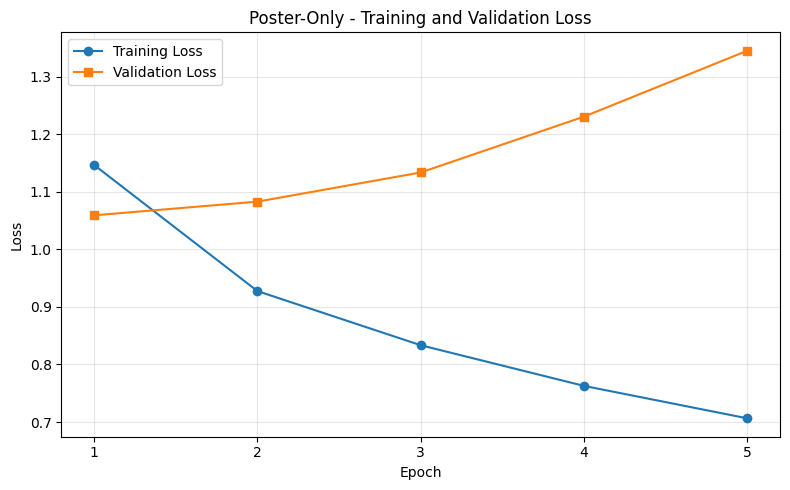

Saved: /content/drive/MyDrive/MM_IMDb_Project/results/posteronly_loss_curve.png


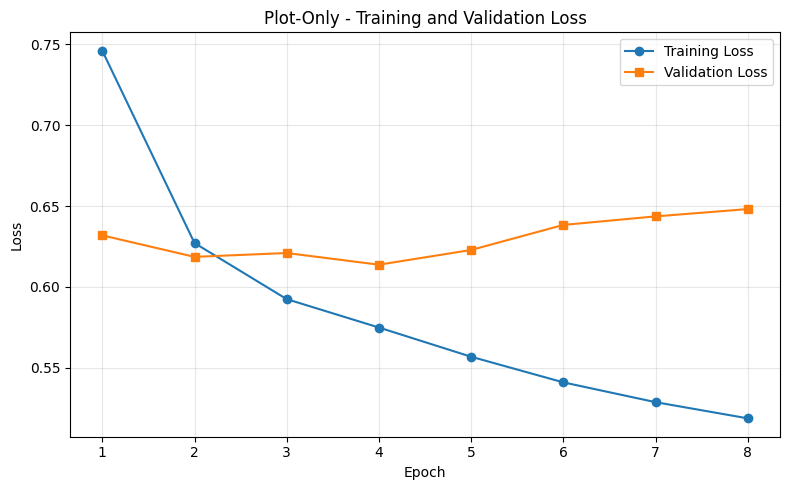

Saved: /content/drive/MyDrive/MM_IMDb_Project/results/plotonly_loss_curve.png


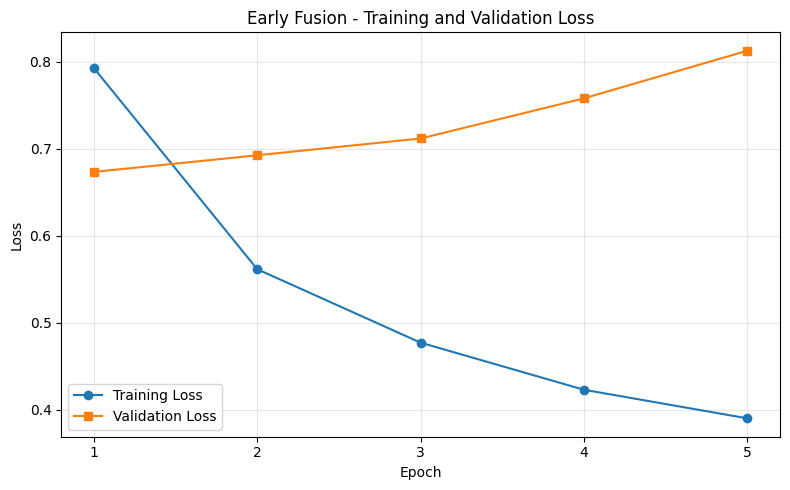

Saved: /content/drive/MyDrive/MM_IMDb_Project/results/early_fusion_loss_curve.png


In [65]:
# ============================================================
# TRAINING AND VALIDATION LOSS CURVES
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd
import os

history_configs = {
    "Poster-Only": {
        "file": "poster_only_training_history.csv",
        "train_col": "train_loss",
        "val_col": "val_loss"
    },
    "Plot-Only": {
        "file": "plot_only_training_history.csv",
        "train_col": "training_loss",
        "val_col": "validation_loss"
    },
    "Early Fusion": {
        "file": "early_fusion_training_history.csv",
        "train_col": "training_loss",
        "val_col": "validation_loss"
    }
}

for model_name, config in history_configs.items():

    history_path = os.path.join(
        RESULTS_DIR, config["file"]
    )

    history = pd.read_csv(history_path)

    plt.figure(figsize=(8, 5))

    plt.plot(
        history["epoch"],
        history[config["train_col"]],
        marker="o",
        label="Training Loss"
    )

    plt.plot(
        history["epoch"],
        history[config["val_col"]],
        marker="s",
        label="Validation Loss"
    )

    plt.title(f"{model_name} - Training and Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.xticks(history["epoch"])
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    filename = (
        model_name.lower().replace("-", "").replace(" ", "_")
        + "_loss_curve.png"
    )

    save_path = os.path.join(RESULTS_DIR, filename)

    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

    print("Saved:", save_path)

Class imbalance analysis

In [66]:
# ============================================================
# CLASS IMBALANCE VS MODEL PERFORMANCE
# ============================================================

# Number of positive training examples for each genre
genre_counts = y_train.sum(axis=0)

imbalance_df = pd.DataFrame({
    "Genre": genre_names,
    "Training Samples": genre_counts.astype(int)
})

# Add Late Fusion test F1 scores
late_f1 = genre_f1_comparison["Late Fusion"]

imbalance_df["Late Fusion F1"] = (
    imbalance_df["Genre"].map(late_f1)
)

# Sort by training frequency
imbalance_df = imbalance_df.sort_values(
    "Training Samples",
    ascending=False
)

# Calculate correlation
correlation = imbalance_df[
    ["Training Samples", "Late Fusion F1"]
].corr().iloc[0, 1]

# Save results
imbalance_df.to_csv(
    os.path.join(RESULTS_DIR, "class_imbalance_analysis.csv"),
    index=False
)

print("Class imbalance analysis")
display(imbalance_df.round(4))

print("\nCorrelation between training frequency and Late Fusion F1:")
print(round(correlation, 4))

Class imbalance analysis


,Genre,Training Samples,Late Fusion F1
0,Drama,9777,0.5485
1,Comedy,6014,0.6006
2,Romance,3754,0.5185
3,Thriller,3634,0.5457
4,Crime,2686,0.6460
5,Action,2485,0.6424
6,Adventure,1897,0.5605
7,Horror,1892,0.6888
8,Documentary,1458,0.7903
9,Mystery,1440,0.4724



Correlation between training frequency and Late Fusion F1:
0.1576


Save your experimental results

In [67]:
# ============================================================
# SAVE FINAL EXPERIMENTAL DATA
# ============================================================

# Save test probabilities, actual labels and model thresholds
final_predictions_path = os.path.join(
    RESULTS_DIR,
    "final_test_predictions.npz"
)

np.savez_compressed(
    final_predictions_path,
    y_test=y_test,
    poster_probabilities=poster_test_probabilities,
    plot_probabilities=plot_test_probabilities,
    early_fusion_probabilities=fusion_test_probabilities,
    late_fusion_probabilities=late_test_probabilities,
    poster_threshold=0.60,
    plot_threshold=0.75,
    early_fusion_threshold=0.80,
    late_fusion_threshold=0.70
)

print("Final test predictions saved:", final_predictions_path)

# Save final metrics
test_results_df.to_csv(
    os.path.join(RESULTS_DIR, "final_test_results.csv"),
    index=False
)

print("Final test metrics saved.")

# List important result files
print("\nFinal result files:")
for filename in sorted(os.listdir(RESULTS_DIR)):
    print(filename)

Final test predictions saved: /content/drive/MyDrive/MM_IMDb_Project/results/final_test_predictions.npz
Final test metrics saved.

Final result files:
class_imbalance_analysis.csv
data_quality_summary.csv
dataset_splits.npz
distilbert_text_embeddings.npy
early_fusion_best_model.pth
early_fusion_loss_curve.png
early_fusion_optimal_threshold.npy
early_fusion_threshold_results.csv
early_fusion_training_history.csv
final_test_predictions.npz
final_test_results.csv
genre_ap_comparison.csv
genre_f1_comparison.csv
image_feature_scaler.pkl
late_fusion_best_alpha.npy
late_fusion_error_analysis.csv
late_fusion_normalised_errors.csv
late_fusion_optimal_threshold.npy
late_fusion_threshold_results.csv
per_genre_ap_heatmap.png
per_genre_f1_heatmap.png
per_genre_performance.csv
plot_only_best_model.pth
plot_only_threshold_results.csv
plot_only_training_history.csv
plot_optimal_threshold.npy
plotonly_loss_curve.png
poster_only_best_model.pth
poster_only_training_history.csv
poster_optimal_threshold.np